# Do stocks in the same group move together?

We compare **daily stock returns from 8 September 2021 to 8 September 2026**.
The main question is whether group peers move together more than stocks in different groups.
We also check shared bad days, changes over time, and similarities in return patterns.

**Data:** adjusted prices from `Data/BMG9156K1018_10.09.2026_14.59.34.csv`.
**Scope:** a selected set of stocks with good five-year coverage, not the historical OSEBX.

Run from top to bottom. Outputs show the main results; detailed audit tables remain in variables.

<details>
<summary>Method details and sources</summary>

**Financial input:** `Data/BMG9156K1018_10.09.2026_14.59.34.csv` only.
**Window:** 8 September 2021–8 September 2026, inclusive. **Eligibility:** valid
adjusted prices at both boundaries and at least 95% of XOSL sessions. One qualifying
share class per identified company is selected by five-year NOK turnover.

All returns are calculated here from `AdjustedPrice`. The first code cell controls
optional natural cubic interpolation of whole internal price gaps up to five sessions.
The default is `INTERPOLATE_SHORT_GAPS = False`. Stock selection always uses observed
prices, so both modes analyse the same stocks. No supplied `lnDelta*` fields, forward
filling, additional price adjustments, or automatic outlier removal are used. Endpoint and coverage selection introduce survivorship and
availability bias: results describe this selected dataset, not the historical OSEBX.

Run `uv sync --locked` from the repository root, then run all cells
using the root `.venv` kernel.
The bootstrap uses 1,000 draws at each of three block lengths; DTW covers every
supported stock pair and 20-session window. Runtime and package versions are recorded.

</details>


Set `INTERPOLATE_SHORT_GAPS` in the first code cell, then restart and run all cells.
Section 12 saves each mode and compares matching runs. Interpolation is a retrospective
EDA sensitivity experiment: estimated returns are flagged and must not be treated as
observed movements or interpolated across modelling train/validation/test boundaries.


### Choose the grouping level

Set GROUPING_LEVEL in the first code cell to Industry (default) or Supersector.
Both use Data/stock_sector_mapping.csv, including the two user-confirmed manual
bank classifications. Original uses the supplied-sector labels. Financial
observations, eligibility, share-class selection, returns, and date panels remain
identical across levels; only group membership and display order change.

The current sample has 11 Industries and 19 Supersectors. A singleton remains in
across-group comparisons but has no internal estimate. The mapping is retrospective,
not historical membership for 2021–2026. ICB outputs are isolated from the original
interpolation results and thesis figures. Internal sector-named table columns
refer to the grouping level selected above.

Pair orientations remain fixed across grouping levels; heatmaps alone reorder stocks for display.


In [1]:
GROUPING_LEVEL = "Supersector"  # Industry, Supersector, or Original (supplied sectors)
INTERPOLATE_SHORT_GAPS = False
MAX_INTERPOLATION_GAP = 5

from pathlib import Path
from itertools import combinations
from time import perf_counter
from importlib.metadata import version
import hashlib
import gzip
import json
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import SymLogNorm
from scipy import stats
from scipy.interpolate import CubicSpline
from scipy.spatial.distance import pdist, squareform
from sklearn.covariance import LedoitWolf
from sklearn.decomposition import PCA
from threadpoolctl import threadpool_limits
import exchange_calendars as xcals
from tslearn.metrics import cdist_dtw, dtw, dtw_path
from IPython.display import display

SOURCE_NAME = "BMG9156K1018_10.09.2026_14.59.34.csv"
START = pd.Timestamp("2021-09-08")
END = pd.Timestamp("2026-09-08")
COVERAGE = 0.95
MIN_PAIR = 252
MIN_TAIL = 1000
TAIL_LEVEL = 0.05
MIN_TAIL_EVENTS = 20
BOOT_DRAWS = 1000
BOOT_BLOCKS = (5, 20, 63)
SEED = 2026
WINDOW = 20
DTW_RADIUS = 2
MIN_DTW_WINDOWS = 10
BOUNDARY_FLAG = 0.20  # Simple-return inspection threshold, not a deletion rule.

root = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "Data" / SOURCE_NAME).is_file())
source = root / "Data" / SOURCE_NAME
assert GROUPING_LEVEL in ("Industry", "Supersector", "Original")
mapping_path = root / "Data" / "stock_sector_mapping.csv"
mapping_hash = None
source_digest = hashlib.sha256()
with source.open("rb") as handle:
    for chunk in iter(lambda: handle.read(1024 * 1024), b""):
        source_digest.update(chunk)
financial_source_sha256 = source_digest.hexdigest()
packages = ["numpy", "pandas", "scipy", "scikit-learn", "matplotlib",
            "exchange_calendars", "tslearn", "threadpoolctl"]
package_versions = pd.Series({p: version(p) for p in packages}, name="version")
plt.rcParams.update({"figure.dpi": 100, "axes.grid": False})
pd.set_option("display.max_columns", 10)
pd.set_option("display.max_rows", 12)
pd.set_option("display.max_colwidth", 70)
pd.set_option("display.precision", 3)
started = perf_counter()
print(f"Data: {SOURCE_NAME} | {START.date()} to {END.date()}")
print(f"Grouping: {GROUPING_LEVEL}; interpolation is controlled independently.")

Data: BMG9156K1018_10.09.2026_14.59.34.csv | 2021-09-08 to 2026-09-08
Grouping: Supersector; interpolation is controlled independently.


## 1. Join each stock's price history

**What:** Link old and new security codes when the identifiers support a continuation.
**Why:** A code change should not make one stock look like two short histories.
Separate share classes and uncertain matches stay separate.

<details>
<summary>Method details and sources</summary>

`CompanyId` identifies an issuer and `SecurityId` supports share-class continuity.
Only singleton, consistent identifier pairs and nonoverlapping ISIN date spans are
joined automatically. Overlapping classes remain separate. The explicit mappings
below reuse [adjusted_price_histories.ipynb](../4stocks_experiment/adjusted_price_histories.ipynb);
they are repository-established mappings, not new independent issuer verification.
Kongsberg's replacement lacks both identifiers. Its mapping is also documented in
[EDA_returns_dependence.ipynb](EDA_returns_dependence.ipynb).

Unresolved histories are retained as separate ISINs. Consequently some genuine
continuations may fail coverage; neither matching names nor price proximity proves
identity. Identifier histories and mapping evidence remain available for review.

</details>


In [2]:
columns = ["Date", "ISIN", "SecurityId", "CompanyId", "Name", "Sector",
           "AdjustedPrice", "Turnover", "Currency"]
data = pd.read_csv(source, sep=";", decimal=",", usecols=columns, low_memory=False)
data["Date"] = pd.to_datetime(data["Date"], format="%Y-%m-%d")
for col in ["ISIN", "Name", "Sector", "Currency"]:
    data[col] = data[col].str.strip().replace("", pd.NA)
assert data["Date"].notna().all() and data["ISIN"].notna().all()
assert data["Date"].max() == END
assert data["Currency"].dropna().eq("NOK").all(), "Review turnover currency before ranking."
data = data.sort_values(["Date", "ISIN"], kind="stable")


def distinct_ids(values: pd.Series) -> tuple:
    """Retain all nonmissing source identities for a security."""
    return tuple(sorted(values.dropna().unique()))


profiles = data.groupby("ISIN", sort=True).agg(
    first=("Date", "min"), last=("Date", "max"),
    company_ids=("CompanyId", distinct_ids), security_ids=("SecurityId", distinct_ids),
    latest_name=("Name", "last"), latest_sector=("Sector", "last"),
)
history = {isin: {isin} for isin in profiles.index}
link_evidence = dict.fromkeys(profiles.index, "standalone ISIN; no accepted predecessor link")


def join_isins(isins: list[str], evidence: str) -> bool:
    """Join whole components only when every member's recorded span is disjoint."""
    if all(history[i] == history[isins[0]] for i in isins):
        return True
    members = set().union(*(history[i] for i in isins))
    spans = profiles.loc[sorted(members)].sort_values("first")
    if not spans["first"].iloc[1:].reset_index(drop=True).gt(
        spans["last"].iloc[:-1].reset_index(drop=True)
    ).all():
        return False
    for isin in members:
        history[isin] = members
        if not link_evidence[isin].startswith("explicit repository mapping"):
            link_evidence[isin] = evidence
    return True


explicit = {
    "Kongsberg": ["NO0003043309", "NO0013536151"],
    "Frontline": ["BMG368191034", "BMG3682E1012", "BMG3682E1921", "CY0200352116"],
    "Tomra": ["NO0005668905", "NO0012470089"],
}
for name, isins in explicit.items():
    assert set(isins).issubset(profiles.index)
    assert join_isins(isins, f"explicit repository mapping: {name}")

stable = profiles.loc[profiles["company_ids"].map(len).eq(1)
                      & profiles["security_ids"].map(len).eq(1)]
unresolved_identifier_groups = []
for keys, group in stable.groupby(["company_ids", "security_ids"]):
    if len(group) > 1 and not join_isins(
        group.index.tolist(), "same singleton CompanyId/SecurityId; disjoint spans"
    ):
        unresolved_identifier_groups.append({"identifiers": str(keys),
                                             "ISINs": tuple(group.index)})

stock_for_isin = {}
for isin, members in history.items():
    current = profiles.loc[sorted(members)].sort_values(["last", "first"]).index[-1]
    stock_for_isin[isin] = current
data["stock_id"] = data["ISIN"].map(stock_for_isin)
endpoint_isins = set(data.loc[data["Date"].eq(END), "ISIN"])
candidates = sorted({stock_for_isin[i] for i in endpoint_isins})
candidate_data = data.loc[data["stock_id"].isin(candidates)]
metadata = candidate_data.groupby("stock_id").agg(
    name=("Name", "last"), company_id=("CompanyId", "last"), sector=("Sector", "last"),
    source_start=("Date", "min"), source_end=("Date", "max"),
    historical_isins=("ISIN", "nunique"), sector_labels=("Sector", distinct_ids),
)
metadata["endpoint_isin"] = metadata.index
metadata["sector_changed"] = metadata["sector_labels"].map(len).gt(1)
lineage = profiles.reset_index()
lineage["stock_id"] = lineage["ISIN"].map(stock_for_isin)
lineage["link_evidence"] = lineage["ISIN"].map(link_evidence)
lineage["endpoint_candidate"] = lineage["stock_id"].isin(candidates)
lineage["joined"] = lineage["ISIN"].map(lambda i: len(history[i]) > 1)
print(f"Loaded {len(data):,} rows; reconstructed {len(candidates)} candidate histories.")
print(f"Joined histories: {lineage.loc[lineage.endpoint_candidate & lineage.joined, 'stock_id'].nunique()}; "
      f"unresolved identifier groups: {len(unresolved_identifier_groups)}.")


Loaded 1,876,617 rows; reconstructed 292 candidate histories.
Joined histories: 14; unresolved identifier groups: 0.


## 2. Keep stocks with enough usable data

**What:** Check trading days, handle duplicate records, and keep stocks with valid endpoints and at least 95% price coverage.
**Why:** Missing prices and conflicting records can distort the comparisons.
The table shows how many stocks remain after each filter.

<details>
<summary>Method details and sources</summary>

The [exchange_calendars](https://github.com/gerrymanoim/exchange_calendars) XOSL
calendar supplies expected trading sessions; it is a maintained calendar implementation,
not an independently checked exchange notice for every date. Source rows on other
dates are counted and excluded. The immediately preceding session supplies the initial
return when available. Coverage uses prices within the requested window only.

Identical repeated prices are counted once. Different recorded values for the same
stock/session, including a missing value alongside a price, are masked as conflicts.
Nonfinite and nonpositive prices are unavailable. Turnover is also deduplicated per
stock/session; conflicting, negative, or nonfinite turnover is unavailable for ranking.

</details>


In [3]:
calendar = xcals.get_calendar("XOSL", start=START - pd.Timedelta(days=14), end=END)
sessions = calendar.sessions_in_range(START, END).tz_localize(None)
previous_session = calendar.previous_session(sessions[0]).tz_localize(None)
price_sessions = sessions.insert(0, previous_session)
assert sessions[0] == START and sessions[-1] == END
in_window = data["Date"].between(START, END)
non_sessions = data.loc[in_window & ~data["Date"].isin(sessions)]
calendar_audit = non_sessions.groupby("Date").size().rename("excluded_source_rows").to_frame()
print(f"Expected sessions: {len(sessions):,}; preceding session: {previous_session.date()}")
print(f"Excluded non-session source rows: {len(non_sessions):,} across {len(calendar_audit)} dates")

raw = candidate_data.loc[candidate_data["Date"].isin(price_sessions)].copy()
keys = ["stock_id", "Date"]
grouped = raw.groupby(keys, sort=True)
price_variants = grouped["AdjustedPrice"].nunique(dropna=False)
turnover_variants = grouped["Turnover"].nunique(dropna=False)
clean = raw.drop_duplicates(keys).set_index(keys).sort_index()
clean["raw_price"] = clean["AdjustedPrice"]
clean["price_conflict"] = price_variants.gt(1)
clean["duplicate_rows"] = grouped.size() - 1
clean["recorded_invalid"] = ~(np.isfinite(clean["raw_price"]) & clean["raw_price"].gt(0))
clean["price"] = clean["raw_price"].where(~clean["price_conflict"] & ~clean["recorded_invalid"])
clean["usable_turnover"] = clean["Turnover"].where(
    turnover_variants.eq(1) & np.isfinite(clean["Turnover"]) & clean["Turnover"].ge(0)
)
all_prices = clean["price"].unstack("stock_id").reindex(index=price_sessions, columns=candidates)
recorded = clean["ISIN"].unstack("stock_id").reindex(index=price_sessions, columns=candidates).notna()
prices_in_window = all_prices.loc[sessions]
all_returns = np.log(all_prices).diff().loc[sessions]
window_clean = clean.loc[clean.index.get_level_values("Date").isin(sessions)]

audit = metadata.copy()
audit["expected_sessions"] = len(sessions)
audit["available_prices"] = prices_in_window.count()
audit["coverage_pct"] = 100 * audit["available_prices"] / len(sessions)
audit["absent_records"] = (~recorded.loc[sessions]).sum()
audit["recorded_unavailable_prices"] = (recorded.loc[sessions] & prices_in_window.isna()).sum()
audit["missing_prices"] = prices_in_window.isna().sum()
audit["price_conflict_sessions"] = window_clean["price_conflict"].groupby(level=0).sum().reindex(candidates, fill_value=0)
audit["recorded_invalid_sessions"] = window_clean["recorded_invalid"].groupby(level=0).sum().reindex(candidates, fill_value=0)
audit["duplicate_rows"] = window_clean["duplicate_rows"].groupby(level=0).sum().reindex(candidates, fill_value=0)
audit["missing_returns"] = all_returns.isna().sum()
audit["zero_return_fraction"] = all_returns.eq(0).sum().div(all_returns.count())
audit["boundary_ok"] = prices_in_window.iloc[0].notna() & prices_in_window.iloc[-1].notna()
audit["coverage_ok"] = audit["available_prices"].ge(np.ceil(COVERAGE * len(sessions)))
audit["five_year_turnover"] = window_clean["usable_turnover"].groupby(level=0).sum(min_count=1).reindex(candidates)
audit["missing_turnover_sessions"] = len(sessions) - window_clean["usable_turnover"].groupby(level=0).count().reindex(candidates, fill_value=0)
audit["coverage_eligible"] = audit["boundary_ok"] & audit["coverage_ok"]
eligible = audit.loc[audit["coverage_eligible"]].copy()
# Missing issuer IDs stay distinct; they cannot be collapsed by company-name similarity.
eligible["issuer_key"] = [f"company:{int(c)}" if pd.notna(c) else f"unidentified:{i}"
                          for i, c in eligible["company_id"].items()]
assert eligible["five_year_turnover"].notna().all(), "Review unavailable turnover before class selection."
ranked = eligible.sort_values(["five_year_turnover", "endpoint_isin"], ascending=[False, True])
selected = ranked.drop_duplicates("issuer_key").sort_values(["sector", "name"], na_position="last")
stock_ids = selected.index.tolist()
audit["selected"] = audit.index.isin(stock_ids)
audit["status"] = np.select(
    [~audit["boundary_ok"], ~audit["coverage_ok"], ~audit["selected"]],
    ["boundary unavailable", "coverage below 95%", "other qualifying share class selected"],
    default="selected",
)
lineage["selection_status"] = lineage["stock_id"].map(audit["status"]).fillna("no endpoint observation")
funnel = pd.Series({
    "Endpoint ISINs": len(endpoint_isins), "Reconstructed candidate histories": len(audit),
    "Valid boundary prices": int(audit["boundary_ok"].sum()),
    "Boundaries and >=95% price coverage": len(eligible), "Selected share classes": len(selected),
}, name="stocks").to_frame()
display(funnel.rename(columns={"stocks": "Stocks remaining"}))
print(f"Selected {len(selected)} stocks; {len(audit) - len(eligible)} failed endpoint/coverage checks; "
      f"{len(eligible) - len(selected)} additional qualifying share classes excluded.")


# Apply the grouping after observed-price eligibility and share-class selection.
stock_ids_before_grouping = stock_ids.copy()
selected_ids_before_grouping = set(stock_ids)
selected["original_sector"] = selected["sector"]
grouping_mapping = None
if GROUPING_LEVEL != "Original":
    mapping_input = pd.read_csv(mapping_path, dtype=str, keep_default_na=False)
    assert mapping_input["ISIN"].is_unique
    grouping_mapping = mapping_input.loc[
        mapping_input["ISIN"].eq(mapping_input["stock_id"])].set_index("stock_id")
    assert grouping_mapping.index.is_unique
    mapping_hash = hashlib.sha256(mapping_path.read_bytes()).hexdigest()
    missing_ids = selected.index.difference(grouping_mapping.index)
    assert missing_ids.empty, f"Selected stocks missing from mapping: {missing_ids.tolist()}"
    mapped = grouping_mapping.loc[selected.index]
    assert mapped["financial_source"].eq(SOURCE_NAME).all()
    assert mapped["financial_source_sha256"].eq(financial_source_sha256).all(), (
        "Mapping was built from a different financial source; inspect it before continuing.")
    assert mapped["classification_status"].isin(["verified", "manual"]).all(), (
        "Resolve selected-stock classifications explicitly; do not drop stocks for mapping coverage.")
    prefix = GROUPING_LEVEL.lower()
    selected["sector"] = mapped[f"icb_{prefix}_name"]
    selected["group_code"] = mapped[f"icb_{prefix}_code"]
    selected["classification_status"] = mapped["classification_status"]
    selected["classification_note"] = mapped["classification_note"]
    assert selected["sector"].ne("").all() and selected["group_code"].ne("").all()
    assert selected.groupby("group_code")["sector"].nunique().eq(1).all()
    selected = selected.sort_values(["group_code", "name"])
else:
    selected = selected.sort_values(["sector", "name"], na_position="last")
stock_ids = stock_ids_before_grouping.copy()
assert set(stock_ids) == selected_ids_before_grouping
group_counts = selected.groupby("sector").size().rename("Stocks").to_frame()
group_counts["Possible within-group pairs"] = group_counts["Stocks"] * (group_counts["Stocks"] - 1) // 2
group_counts["Internal estimate available"] = group_counts["Stocks"].ge(2)
print(f"{GROUPING_LEVEL}: {len(group_counts)} groups; {int(group_counts['Stocks'].eq(1).sum())} singletons.")
with pd.option_context("display.max_rows", None):
    display(group_counts.rename_axis(GROUPING_LEVEL))
if GROUPING_LEVEL != "Original":
    print("Classification provenance:", selected["classification_status"].value_counts().to_dict())
singletons = group_counts.index[group_counts["Stocks"].eq(1)]
if len(singletons):
    print("Singletons have no internal correlation estimate:")
    display(selected.loc[selected["sector"].isin(singletons), ["name", "sector"]])


Expected sessions: 1,257; preceding session: 2021-09-07
Excluded non-session source rows: 6,777 across 24 dates


,Stocks remaining
Endpoint ISINs,292
Reconstructed candidate histories,292
Valid boundary prices,205
Boundaries and >=95% price coverage,197
Selected share classes,195


Selected 195 stocks; 95 failed endpoint/coverage checks; 2 additional qualifying share classes excluded.
Supersector: 19 groups; 1 singletons.


,Stocks,Possible within-group pairs,Internal estimate available
Supersector,,,
Automobiles and Parts,1,0,False
Banks,24,276,True
Basic Resources,7,21,True
Chemicals,5,10,True
Construction and Materials,6,15,True
Consumer Products and Services,4,6,True
Energy,35,595,True
Financial Services,6,15,True
"Food, Beverage and Tobacco",21,210,True


Classification provenance: {'verified': 193, 'manual': 2}
Singletons have no internal correlation estimate:


,name,sector
stock_id,,
NO0003033102,KONGSBERG AUTOMOT,Automobiles and Parts


### 2a. Optional short-gap interpolation

**What:** With the switch on, fill whole internal gaps of at most five consecutive
exchange sessions using a natural cubic spline of adjusted prices. Calculate returns
after filling prices. The observed-only eligibility and share-class choices stay fixed.
**Why:** Recover usable 20-return windows and measure how much the resulting estimates change.

The raw prices, raw returns, and selection audit are retained separately. Longer gaps,
leading/trailing gaps, and nonpositive spline estimates are not filled. Both price and
return masks identify estimates; observed prices and already-available returns stay
unchanged. A missing price also affects the following day's return.

This is interpolation on session positions, not calendar-day spacing. The spline uses
later observations and imposes a smooth path where the actual daily movement is unknown.
It can alter volatility, tail and dependence estimates; it does not add observed prices.
The [SciPy CubicSpline documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.interpolate.CubicSpline.html)
describes the natural boundary condition and disabling extrapolation.

In [4]:
def interpolate_short_price_gaps(frame: pd.DataFrame, max_gap: int) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Fill whole bounded short runs with positive natural-cubic price estimates."""
    filled = frame.copy()
    records = []
    for stock_id in frame.columns:
        values = frame[stock_id].to_numpy()
        observed = np.flatnonzero(np.isfinite(values))
        spline = (CubicSpline(observed, values[observed], bc_type="natural", extrapolate=False)
                  if len(observed) >= 4 else None)
        changes = np.diff((~np.isfinite(values)).astype(int), prepend=0, append=0)
        for first, stop in zip(np.flatnonzero(changes == 1), np.flatnonzero(changes == -1)):
            internal = first > 0 and stop < len(values)
            eligible_gap = internal and stop - first <= max_gap
            accepted = False
            if eligible_gap and spline is not None:
                estimates = spline(np.arange(first, stop))
                if np.isfinite(estimates).all() and (estimates > 0).all():
                    filled.iloc[first:stop, filled.columns.get_loc(stock_id)] = estimates
                    accepted = True
            records.append({"stock_id": stock_id, "start": frame.index[first],
                            "end": frame.index[stop - 1], "sessions": int(stop - first),
                            "internal": internal, "eligible": eligible_gap, "filled": accepted})
    return filled, pd.DataFrame(records)


def twenty_session_counts(frame: pd.DataFrame) -> pd.Series:
    """Count finite return windows on the original grid, without compressing dates."""
    valid = frame.notna().to_numpy()
    rolling = np.lib.stride_tricks.sliding_window_view(valid, WINDOW, axis=0).all(axis=-1)
    blocks = len(frame) // WINDOW
    fixed = valid[:blocks * WINDOW].reshape(blocks, WINDOW, frame.shape[1]).all(axis=1)
    return pd.Series({"Single-stock rolling windows": int(rolling.sum()),
                      "Single-stock non-overlapping windows": int(fixed.sum()),
                      "Joint rolling windows (all stocks)": int(rolling.all(axis=1).sum()),
                      "Joint non-overlapping windows (all stocks)": int(fixed.all(axis=1).sum())})


observed_all_prices = all_prices.copy()
observed_all_returns = all_returns.copy()
observed_prices_in_window = prices_in_window.copy()
if INTERPOLATE_SHORT_GAPS:
    all_prices, interpolation_gap_audit = interpolate_short_price_gaps(
        observed_all_prices, MAX_INTERPOLATION_GAP)
else:
    all_prices = observed_all_prices.copy()
    interpolation_gap_audit = pd.DataFrame()
prices_in_window = all_prices.loc[sessions]
all_returns = np.log(all_prices).diff().loc[sessions]
imputed_price_mask = observed_all_prices.isna() & all_prices.notna()
imputed_return_mask = observed_all_returns.isna() & all_returns.notna()
observed_selected_returns = observed_all_returns[stock_ids]
original_complete_mask = observed_selected_returns.notna().all(axis=1)

interpolation_audit = pd.DataFrame({
    "Observed missing prices": observed_prices_in_window[stock_ids].isna().sum(),
    "Estimated prices": imputed_price_mask.loc[sessions, stock_ids].sum(),
    "Remaining missing prices": prices_in_window[stock_ids].isna().sum(),
    "Estimated returns": imputed_return_mask[stock_ids].sum(),
    "Remaining missing returns": all_returns[stock_ids].isna().sum(),
}).join(selected[["name", "sector"]])
window_coverage = pd.concat({"Observed": twenty_session_counts(observed_selected_returns),
                             "Current mode": twenty_session_counts(all_returns[stock_ids])}, axis=1)
window_coverage["Change"] = window_coverage["Current mode"] - window_coverage["Observed"]
print(f"Short-gap interpolation: {'ON' if INTERPOLATE_SHORT_GAPS else 'OFF'}; "
      f"same {len(stock_ids)} stocks selected using observed coverage.")
print(f"Estimated selected prices: {int(imputed_price_mask.loc[sessions, stock_ids].sum().sum())}; "
      f"estimated daily returns: {int(imputed_return_mask[stock_ids].sum().sum())}.")
display(window_coverage)

Short-gap interpolation: OFF; same 195 stocks selected using observed coverage.
Estimated selected prices: 0; estimated daily returns: 0.


,Observed,Current mode,Change
Single-stock rolling windows,237743,237743,0
Single-stock non-overlapping windows,11904,11904,0
Joint rolling windows (all stocks),468,468,0
Joint non-overlapping windows (all stocks),22,22,0


### Check gaps and changes of security code

**What:** Check price jumps around code changes and count missing prices and returns.
**Why:** Gaps and unexplained jumps can affect the later results.
**Read the plots:** black means a price or return is present. Large changes are flags for review, not automatic errors.

<details>
<summary>Method details and sources</summary>

Boundary returns use the supplied prices across consecutive exchange sessions. A
gap makes that boundary return unavailable; a separate recorded-to-recorded change
is shown for inspection and is not called a daily return. Absolute simple changes of
20% or more are flags, not evidence of an error and not a removal rule.

`absent_records + recorded_unavailable_prices = missing_prices`. Invalid-value and
conflict diagnostic counts may overlap and must not be added to that decomposition.
Return gaps include the session after a missing price. Zero returns remain observed.

</details>


Checked 12 code transitions; 0 changes of at least 20% flagged for review.


,Stocks,Sessions,Missing prices,Missing returns
sample,,,,
Selected stocks,195,1257,506,862
Shared dates only,195,871,0,0


Complete dates retained: 871/1,257; removed: 386 (30.7%).


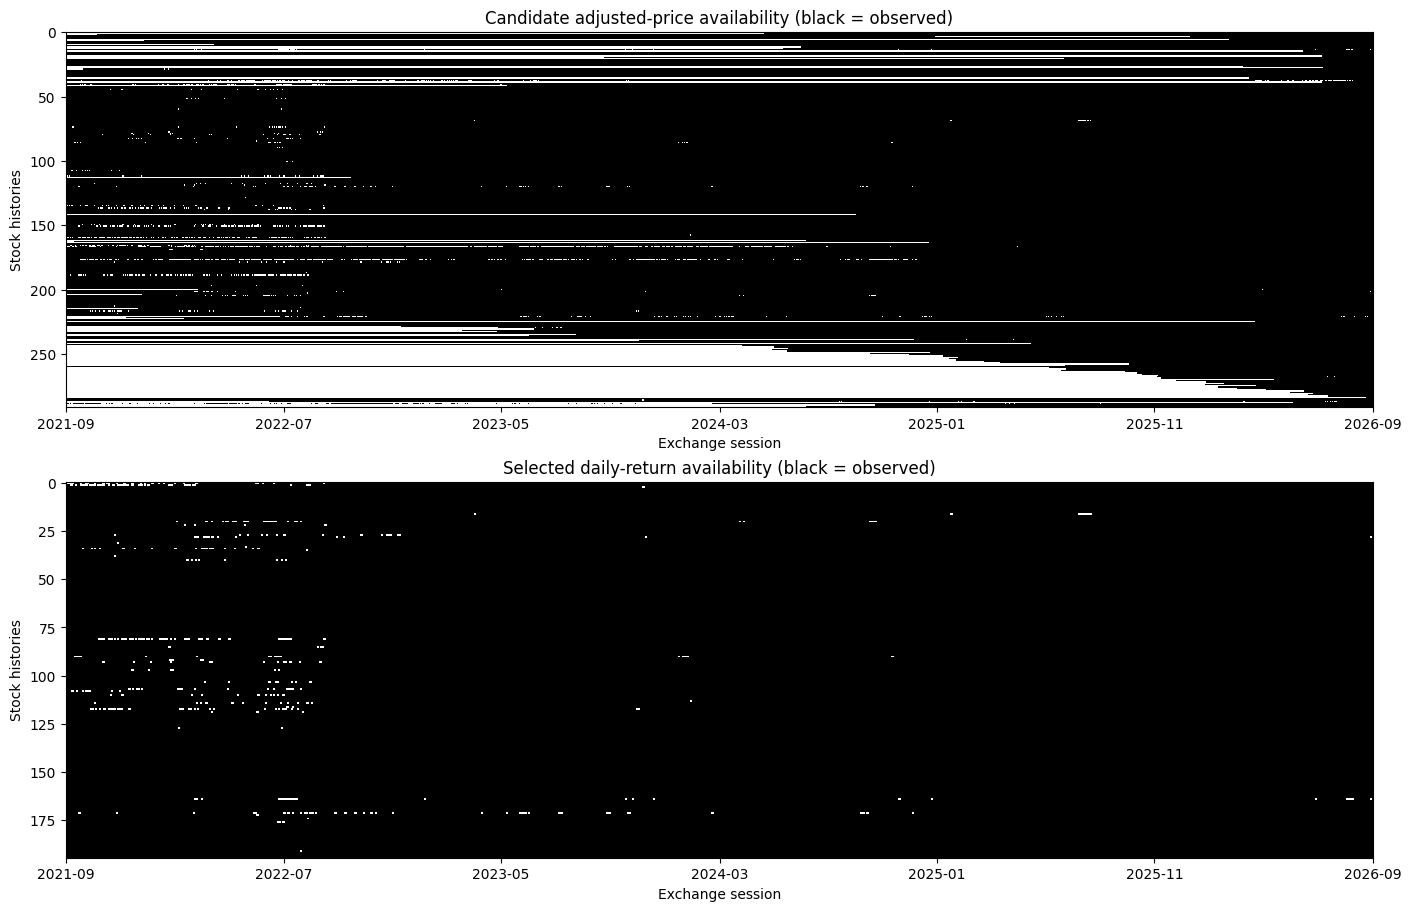

In [5]:
transition_rows = []
for stock_id in candidates:
    component = lineage.loc[lineage["stock_id"].eq(stock_id)].sort_values("first")
    for (_, old), (_, new) in zip(component.iloc[:-1].iterrows(), component.iloc[1:].iterrows()):
        new_rows = clean.loc[(clean["ISIN"].eq(new["ISIN"]))
                             & clean.index.get_level_values("Date").isin(sessions)]
        if new_rows.empty or not (START <= new["first"] <= END):
            continue
        boundary_date = new_rows.index.get_level_values("Date")[0]
        old_rows = clean.loc[clean["ISIN"].eq(old["ISIN"])]
        previous_date = old_rows.index.get_level_values("Date").max() if len(old_rows) else pd.NaT
        old_price = old_rows.iloc[-1]["price"] if len(old_rows) else np.nan
        new_price = new_rows.iloc[0]["price"]
        # Older prices may precede the analysis window; retrieve the last source value.
        if pd.isna(previous_date):
            older = candidate_data.loc[candidate_data["ISIN"].eq(old["ISIN"])]
            previous_date = older["Date"].max()
            vals = older.loc[older["Date"].eq(previous_date), "AdjustedPrice"]
            old_price = vals.iloc[0] if vals.nunique(dropna=False) == 1 else np.nan
        change = new_price / old_price - 1 if np.isfinite(old_price) and old_price > 0 else np.nan
        transition_rows.append({"stock_id": stock_id, "name": audit.loc[stock_id, "name"],
            "old_isin": old["ISIN"], "new_isin": new["ISIN"], "previous_record": previous_date,
            "boundary_date": boundary_date, "old_price": old_price, "new_price": new_price,
            "recorded_change": change, "daily_log_return": all_returns.loc[boundary_date, stock_id],
            "large_change_flag": bool(abs(change) >= BOUNDARY_FLAG),
            "estimated_daily_return": bool(imputed_return_mask.loc[boundary_date, stock_id]),
            "evidence": new["link_evidence"]})
transitions = pd.DataFrame(transition_rows)
print(f"Checked {len(transitions)} code transitions; "
      f"{int(transitions.large_change_flag.sum())} changes of at least 20% flagged for review.")

returns = all_returns.loc[:, stock_ids]
prices = prices_in_window.loc[:, stock_ids]
complete_mask = returns.notna().all(axis=1)
complete = returns.loc[complete_mask]
assert len(complete) >= MIN_PAIR, "Too few complete dates for the planned common-panel analysis."
assert complete.std().gt(0).all(), "Review constant stocks before PCA and covariance estimation."


def missing_summary(label: str, p: pd.DataFrame, r: pd.DataFrame) -> dict:
    """Count missing entries with each table's own explicit denominator."""
    return {"sample": label, "stocks": r.shape[1], "dates": len(r),
            "price_cells": p.size, "price_NaNs": int(p.isna().sum().sum()),
            "price_NaN_pct": 100 * p.isna().sum().sum() / p.size,
            "return_cells": r.size, "return_NaNs": int(r.isna().sum().sum()),
            "return_NaN_pct": 100 * r.isna().sum().sum() / r.size}


missingness = pd.DataFrame([
    missing_summary("All candidate histories", prices_in_window, all_returns),
    missing_summary("After boundary/95% filter", prices_in_window[eligible.index], all_returns[eligible.index]),
    missing_summary("After share-class selection", prices, returns),
    missing_summary("Complete dates; same selected stocks", prices.loc[complete_mask], complete),
]).set_index("sample")
display(missingness.loc[["After share-class selection", "Complete dates; same selected stocks"],
    ["stocks", "dates", "price_NaNs", "return_NaNs"]].rename(
    index={"After share-class selection": "Selected stocks", "Complete dates; same selected stocks": "Shared dates only"},
    columns={"stocks": "Stocks", "dates": "Sessions", "price_NaNs": "Missing prices", "return_NaNs": "Missing returns"}))
print(f"Complete dates retained: {len(complete):,}/{len(returns):,}; "
      f"removed: {(~complete_mask).sum():,} ({100 * (~complete_mask).mean():.1f}%).")
fig, axes = plt.subplots(2, 1, figsize=(14, 9), constrained_layout=True)
for ax, frame, title in zip(axes, [observed_prices_in_window, returns],
                          ["Candidate adjusted-price availability", "Selected daily-return availability"]):
    ax.imshow(frame.notna().T, aspect="auto", interpolation="nearest", cmap="Greys", vmin=0, vmax=1)
    ticks = np.linspace(0, len(frame) - 1, 7).astype(int)
    ax.set_xticks(ticks, frame.index[ticks].strftime("%Y-%m"))
    caption = " (black = available, including estimates)" if INTERPOLATE_SHORT_GAPS and frame is returns else " (black = observed)"
    ax.set(title=title + caption, xlabel="Exchange session", ylabel="Stock histories")
plt.show()
plt.close(fig)

## 3. Compare stocks within and across groups

**What:** Calculate each stock pair's correlation, then compare pairs in the same group with pairs in different groups.
**Why:** This directly checks whether group peers behave more alike.

- **Pearson:** do daily returns move together?
- **Spearman:** do relatively good and bad days line up, using return ranks?
- **Movement size:** do large moves happen together, regardless of direction?

**Read the results:** gap = same-group average minus different-group average.
A positive gap means group peers are more correlated on average.
**Available pairs** uses each pair's shared dates. **Complete dates** uses the same dates for all stocks.

<details>
<summary>Method details and sources</summary>

Pearson measures linear same-day co-movement. Spearman measures monotonic association
of return ranks; it gives extreme magnitudes less influence, but is not immune to
data problems. Correlation of absolute log returns examines coincident movement sizes,
regardless of direction. Zero correlation does not establish independence.

[pandas correlation](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.corr.html)
uses pairwise complete observations. The available-pair matrices therefore have varying
support and need not be positive semidefinite. The complete panel controls the observation
dates, but conditions results on those retained dates; compare both panels.

[Covariance](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.cov.html)
retains daily log-return scale (squared fractional-return units), unlike correlation.
[Ledoit–Wolf](https://scikit-learn.org/stable/modules/generated/sklearn.covariance.LedoitWolf.html)
shrinks the complete-panel covariance; it does not fix missing data or outliers.

Only unique unordered pairs enter summaries. Unknown groups are excluded from group
comparisons. The pair-weighted result compares all internal pairs against all cross-group
pairs. The equally group-weighted result averages internal and group-to-rest means
over groups with both estimates; small and large groups then have equal weight.

</details>


,Dates,Measure,Same group,Different groups,Gap
0,Available pairs,pearson,0.112,0.060,0.052
1,Available pairs,spearman,0.125,0.069,0.057
2,Available pairs,Movement size,0.060,0.031,0.029
3,Complete dates,pearson,0.100,0.050,0.050
4,Complete dates,spearman,0.115,0.059,0.057
5,Complete dates,Movement size,0.050,0.025,0.025


Pearson gap: equal weight per pair versus equal weight per estimable group.


,Each group equal,Each pair equal
Dates,,
Available pairs,0.041,0.052
Complete dates,0.038,0.050


Per-Supersector Pearson correlations on complete dates:


,Supersector,stocks,within_pairs,between_pairs,within_mean,within_median,between_mean,difference
0,Automobiles and Parts,1,0,194,NaN,NaN,0.080,NaN
1,Banks,24,276,4104,0.099,0.063,0.049,0.050
2,Basic Resources,7,21,1316,0.029,0.023,0.040,-0.012
3,Chemicals,5,10,950,0.067,0.042,0.059,0.008
4,Construction and Materials,6,15,1134,0.117,0.114,0.066,0.051
5,Consumer Products and Services,4,6,764,-0.001,0.001,0.036,-0.037
6,Energy,35,595,5600,0.150,0.110,0.057,0.094
7,Financial Services,6,15,1134,0.088,0.090,0.075,0.013
8,"Food, Beverage and Tobacco",21,210,3654,0.079,0.031,0.038,0.041
9,Health Care,13,78,2366,0.021,0.022,0.032,-0.011


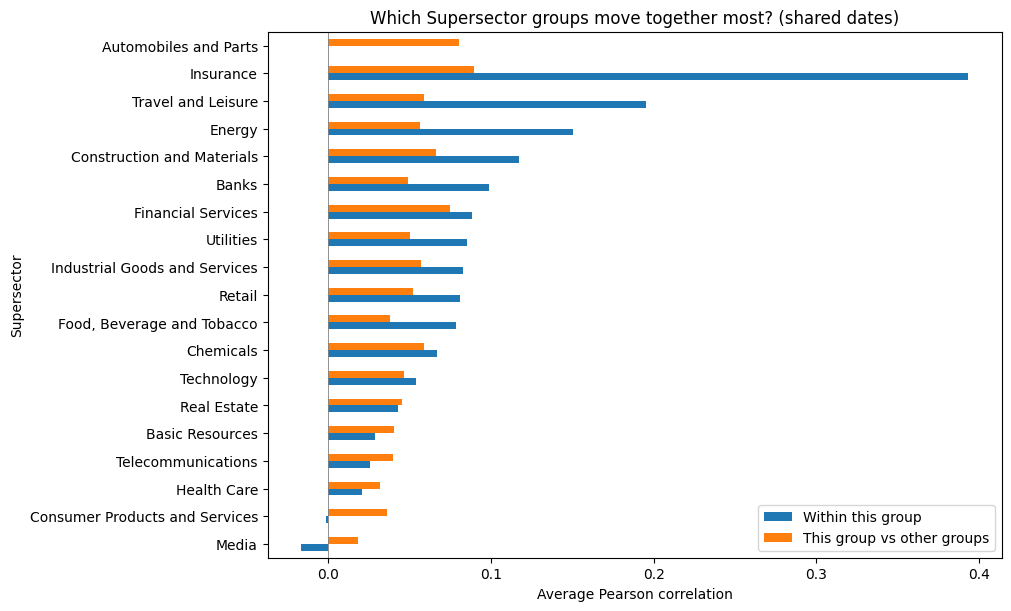

Covariance shrinkage strength: 48.8% (higher means more shrinkage).


In [6]:
def dependence_pairs(frame: pd.DataFrame, absolute: bool = True) -> tuple[dict, pd.DataFrame]:
    """Calculate correlation matrices and the exact paired-date support for each pair."""
    matrices = {"pearson": frame.corr(min_periods=MIN_PAIR),
                "spearman": frame.corr(method="spearman", min_periods=MIN_PAIR)}
    if absolute:
        matrices["absolute"] = frame.abs().corr(min_periods=MIN_PAIR)
    observed = frame.notna().to_numpy()
    n_pairs = observed.astype(np.int32).T @ observed.astype(np.int32)
    rows = []
    for i, j in combinations(range(frame.shape[1]), 2):
        a, b = frame.columns[i], frame.columns[j]
        indices = np.flatnonzero(observed[:, i] & observed[:, j])
        row = {"stock_i": a, "stock_j": b, "name_i": selected.loc[a, "name"],
               "name_j": selected.loc[b, "name"], "sector_i": selected.loc[a, "sector"],
               "sector_j": selected.loc[b, "sector"], "n_pair": len(indices),
               "first_date": frame.index[indices[0]] if len(indices) else pd.NaT,
               "last_date": frame.index[indices[-1]] if len(indices) else pd.NaT}
        row.update({metric: matrix.iloc[i, j] for metric, matrix in matrices.items()})
        rows.append(row)
    matrices["n_pair"] = pd.DataFrame(n_pairs, index=frame.columns, columns=frame.columns)
    pairs = pd.DataFrame(rows)
    pairs["known_sectors"] = pairs[["sector_i", "sector_j"]].notna().all(axis=1)
    pairs["same_sector"] = pairs["known_sectors"] & pairs["sector_i"].eq(pairs["sector_j"])
    return matrices, pairs


def sector_summaries(pairs: pd.DataFrame, metrics: list[str], panel: str) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Compare within/across pairs and give each estimable sector equal macro weight."""
    known = pairs.loc[pairs["known_sectors"]]
    rows, global_rows = [], []
    for metric in metrics:
        local = []
        for sector, stocks in selected.dropna(subset=["sector"]).groupby("sector"):
            internal = known.loc[known["sector_i"].eq(sector) & known["sector_j"].eq(sector), metric].dropna()
            external = known.loc[known["sector_i"].eq(sector) ^ known["sector_j"].eq(sector), metric].dropna()
            local.append({"panel": panel, "metric": metric, "sector": sector, "stocks": len(stocks),
                "within_pairs": len(internal), "between_pairs": len(external),
                "within_mean": internal.mean(), "within_median": internal.median(),
                "between_mean": external.mean(), "between_median": external.median(),
                "difference": internal.mean() - external.mean()})
        rows.extend(local)
        inside = known.loc[known["same_sector"], metric].dropna()
        outside = known.loc[~known["same_sector"], metric].dropna()
        global_rows.append({"panel": panel, "metric": metric, "weighting": "pairs",
            "within_mean": inside.mean(), "between_mean": outside.mean(),
            "difference": inside.mean() - outside.mean(),
            "within_pairs": len(inside), "between_pairs": len(outside)})
        estimable = pd.DataFrame(local).dropna(subset=["within_mean", "between_mean"])
        global_rows.append({"panel": panel, "metric": metric, "weighting": "equal sectors",
            "within_mean": estimable["within_mean"].mean(),
            "between_mean": estimable["between_mean"].mean(),
            "difference": estimable["difference"].mean(), "sectors": len(estimable)})
    return pd.DataFrame(global_rows), pd.DataFrame(rows)


matrices, pair_tables, global_parts, sector_parts = {}, {}, [], []
for label, frame in [("Available pairs", returns), ("Complete dates", complete)]:
    matrices[label], pair_tables[label] = dependence_pairs(frame)
    g, s = sector_summaries(pair_tables[label], ["pearson", "spearman", "absolute"], label)
    global_parts.append(g)
    sector_parts.append(s)
global_comparison = pd.concat(global_parts, ignore_index=True)
sector_comparison = pd.concat(sector_parts, ignore_index=True)
sample_covariances = {"Available pairs": returns.cov(min_periods=MIN_PAIR),
                      "Complete dates": complete.cov()}
lw = LedoitWolf().fit(complete.to_numpy())
shrinkage_covariance = pd.DataFrame(lw.covariance_, index=stock_ids, columns=stock_ids)
correlation_overview = global_comparison.loc[global_comparison.weighting.eq("pairs"),
    ["panel", "metric", "within_mean", "between_mean", "difference"]].rename(columns={
    "panel": "Dates", "metric": "Measure", "within_mean": "Same group", "between_mean": "Different groups", "difference": "Gap"})
correlation_overview["Measure"] = correlation_overview["Measure"].replace({"absolute": "Movement size"})
display(correlation_overview.round(3).reset_index(drop=True))
weighting_overview = global_comparison.loc[global_comparison.metric.eq("pearson"),
    ["panel", "weighting", "difference"]].pivot(index="panel", columns="weighting", values="difference")
print("Pearson gap: equal weight per pair versus equal weight per estimable group.")
display(weighting_overview.rename_axis(index="Dates", columns=None).rename(
    columns={"pairs": "Each pair equal", "equal sectors": "Each group equal"}).round(3))
print(f"Per-{GROUPING_LEVEL} Pearson correlations on complete dates:")
per_group_pearson = sector_comparison.loc[
    sector_comparison.panel.eq("Complete dates") & sector_comparison.metric.eq("pearson"),
    ["sector", "stocks", "within_pairs", "between_pairs", "within_mean", "within_median",
     "between_mean", "difference"]]
with pd.option_context("display.max_rows", None):
    display(per_group_pearson.rename(columns={"sector": GROUPING_LEVEL}).round(4).reset_index(drop=True))
sector_chart = sector_comparison.loc[sector_comparison.panel.eq("Complete dates")
    & sector_comparison.metric.eq("pearson")].sort_values("within_mean")
fig, ax = plt.subplots(figsize=(10, 6), constrained_layout=True)
sector_chart.set_index("sector")[["within_mean", "between_mean"]].rename(columns={
    "within_mean": "Within this group", "between_mean": "This group vs other groups"}).plot.barh(ax=ax)
ax.axvline(0, color="grey", linewidth=0.6)
ax.set(title=f"Which {GROUPING_LEVEL} groups move together most? (shared dates)", xlabel="Average Pearson correlation", ylabel=GROUPING_LEVEL)
plt.show()
plt.close(fig)
print(f"Covariance shrinkage strength: {lw.shrinkage_:.1%} (higher means more shrinkage).")


### How to read the heatmaps

**What:** Show every stock pair to reveal clusters hidden by averages.
**Why:** A group average can hide a few strongly related pairs.

**Red = positive correlation; blue = negative; pale = near zero.** Stocks are grouped by group.
Blocks along the diagonal compare stocks within a group. Grey lines mark group boundaries.
**Yellow/green plots show observation counts, not correlation**; read each colour bar for the count.
Covariance also reflects volatility; its diagonal shows individual variances.
In the final histograms, a curve further right means generally higher correlations on shared dates.


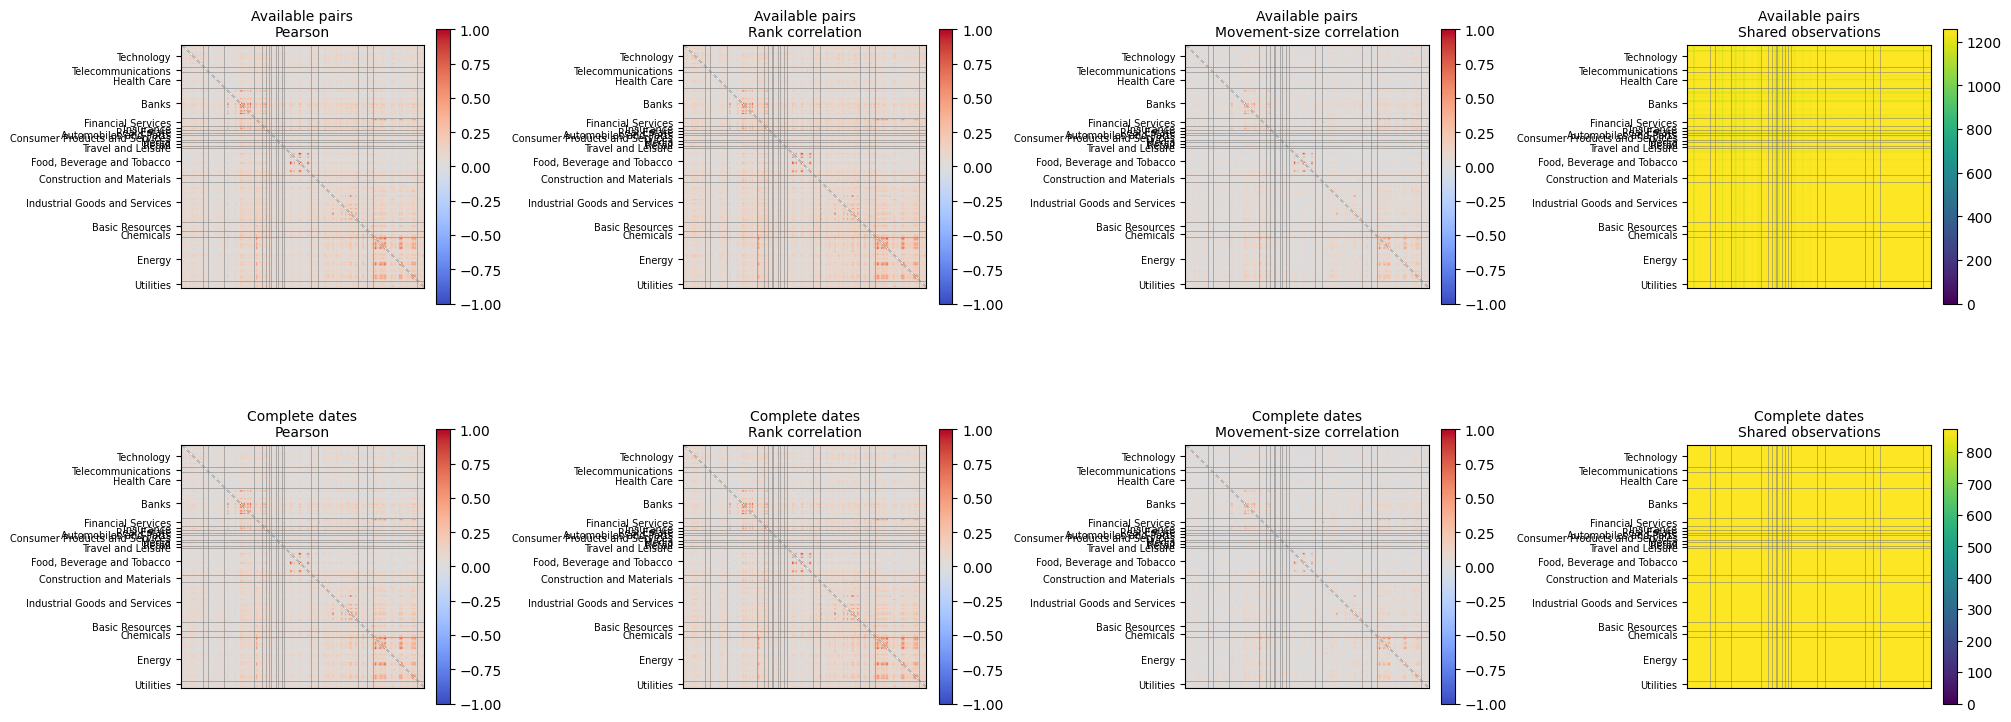

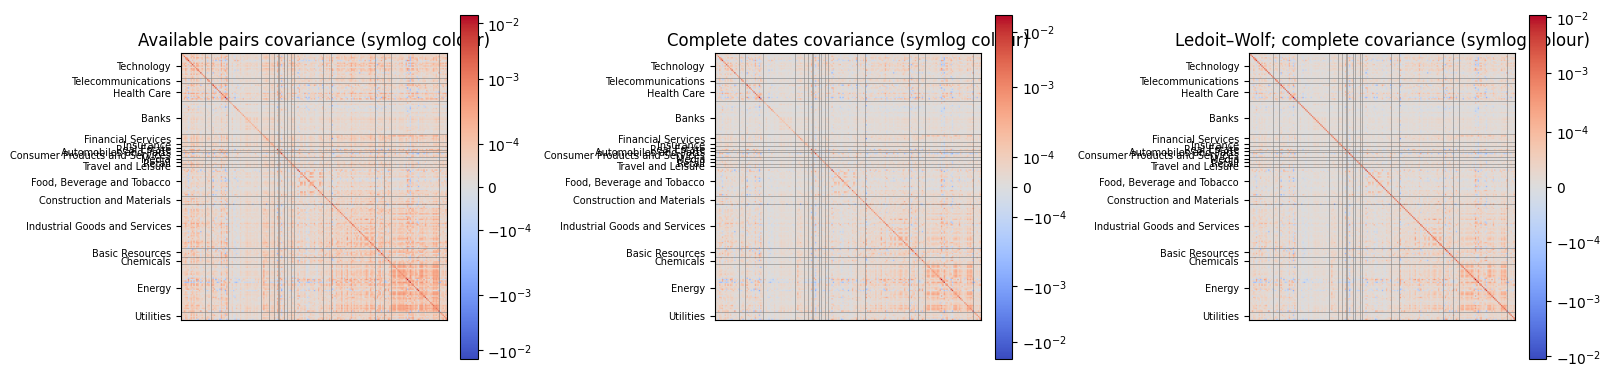

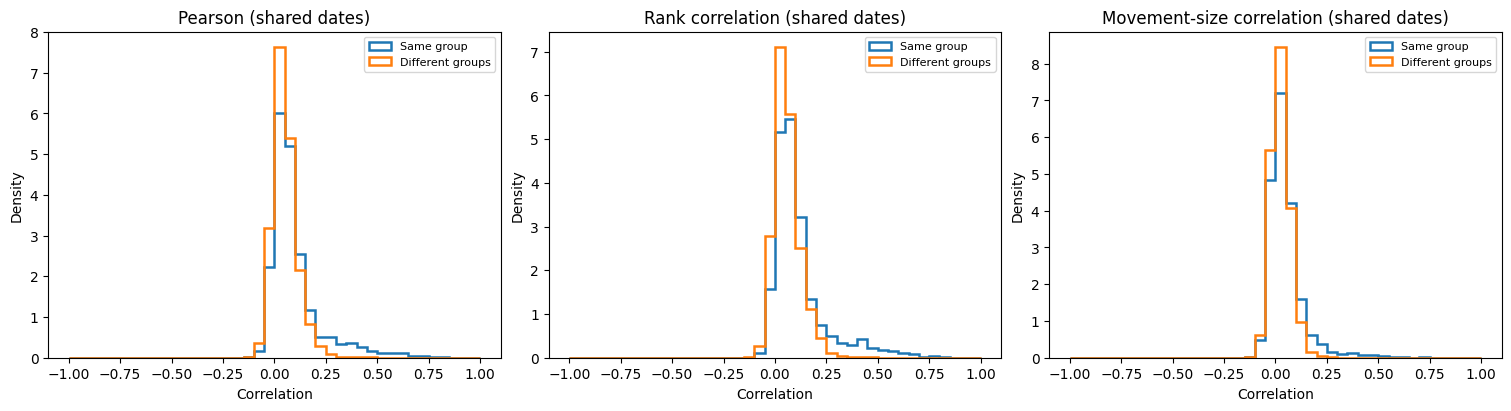

In [7]:
heatmap_order = selected.index.tolist()
sector_labels = selected.loc[heatmap_order, "sector"].fillna("Unknown").to_numpy()
boundaries = np.flatnonzero(sector_labels[1:] != sector_labels[:-1]) + 1
starts = np.r_[0, boundaries]
ends = np.r_[boundaries, len(stock_ids)]


def sector_axes(ax: plt.Axes) -> None:
    """Mark the fixed sector ordering shared by all stock matrices."""
    for boundary in boundaries:
        ax.axhline(boundary - 0.5, color="grey", linewidth=0.4)
        ax.axvline(boundary - 0.5, color="grey", linewidth=0.4)
    ax.set_yticks((starts + ends - 1) / 2, sector_labels[starts], fontsize=7)
    ax.set_xticks([])


fig, axes = plt.subplots(2, 4, figsize=(20, 8), constrained_layout=True)
for row, label in enumerate(matrices):
    for col, metric in enumerate(["pearson", "spearman", "absolute", "n_pair"]):
        matrix = matrices[label][metric].loc[heatmap_order, heatmap_order].copy()
        if metric != "n_pair":
            np.fill_diagonal(matrix.values, np.nan)
        im = axes[row, col].imshow(matrix, cmap="viridis" if metric == "n_pair" else "coolwarm",
                                   vmin=0 if metric == "n_pair" else -1,
                                   vmax=None if metric == "n_pair" else 1)
        metric_title = {"pearson": "Pearson", "spearman": "Rank correlation",
                        "absolute": "Movement-size correlation", "n_pair": "Shared observations"}[metric]
        axes[row, col].set_title(f"{label}\n{metric_title}", fontsize=10)
        sector_axes(axes[row, col])
        fig.colorbar(im, ax=axes[row, col], shrink=0.7)
plt.show()
plt.close(fig)
fig, axes = plt.subplots(1, 3, figsize=(16, 5), constrained_layout=True)
for ax, (label, matrix) in zip(axes, [*sample_covariances.items(), ("Ledoit–Wolf; complete", shrinkage_covariance)]):
    matrix = matrix.loc[heatmap_order, heatmap_order]
    scale = np.nanmax(np.abs(matrix.to_numpy()))
    im = ax.imshow(matrix, cmap="coolwarm", norm=SymLogNorm(linthresh=scale / 100, vmin=-scale, vmax=scale))
    ax.set_title(label + " covariance (symlog colour)")
    sector_axes(ax)
    fig.colorbar(im, ax=ax, shrink=0.7)
plt.show()
plt.close(fig)
fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
for ax, metric in zip(axes, ["pearson", "spearman", "absolute"]):
    pairs = pair_tables["Complete dates"]
    for same, name in [(True, "Same group"), (False, "Different groups")]:
        values = pairs.loc[pairs["known_sectors"] & pairs["same_sector"].eq(same), metric].dropna()
        ax.hist(values, bins=np.linspace(-1, 1, 41), density=True, histtype="step", linewidth=1.8, label=name)
    title = {"pearson": "Pearson", "spearman": "Rank correlation", "absolute": "Movement-size correlation"}[metric]
    ax.set(title=title + " (shared dates)", xlabel="Correlation", ylabel="Density")
    ax.legend(fontsize=8)
plt.show()
plt.close(fig)


## 4. Check how uncertain the group gap is

**What:** Resample blocks of trading days and recalculate the gap 1,000 times per block length.
**Why:** One estimate does not show how sensitive the result is to the observed days.
We keep neighbouring days together and resample all stocks together.

**Read the plots:** dots are estimated gaps; lines are 95% bootstrap intervals.
An interval entirely to the right of zero supports a positive gap under this procedure.

<details>
<summary>Method details and sources</summary>

Stock pairs share companies and are not independent replicates. Circular block
resampling draws consecutive session blocks jointly across every stock. Complete-date
selection happens **after** resampling the original grid, so discarded sessions are
not compressed before building blocks. Pearson and Spearman are recalculated, including
ranks and bootstrap ties, for every draw.

The intervals below are percentile intervals conditional on this selected stock universe
and its missingness. They do not incorporate uncertainty in identity mappings or issuer
selection. Block lengths 5, 20 (primary), and 63 assess sensitivity to temporal dependence.
Circular wrapping and an approximately stable dependence structure within this five-year
period are resampling assumptions; intervals are not causal evidence or multiplicity-adjusted tests.

</details>


Bootstrap block 5: completed 1,000 draws


Bootstrap block 20: completed 1,000 draws


Bootstrap block 63: completed 1,000 draws


Bootstrap runtime: 63.7 seconds


,Block length,Weighting,Gap,95% lower,95% upper
0,5,All pairs,0.050,0.046,0.057
1,5,Equal groups,0.038,0.031,0.046
2,20,All pairs,0.050,0.046,0.056
3,20,Equal groups,0.038,0.031,0.045
4,63,All pairs,0.050,0.046,0.056
5,63,Equal groups,0.038,0.031,0.046


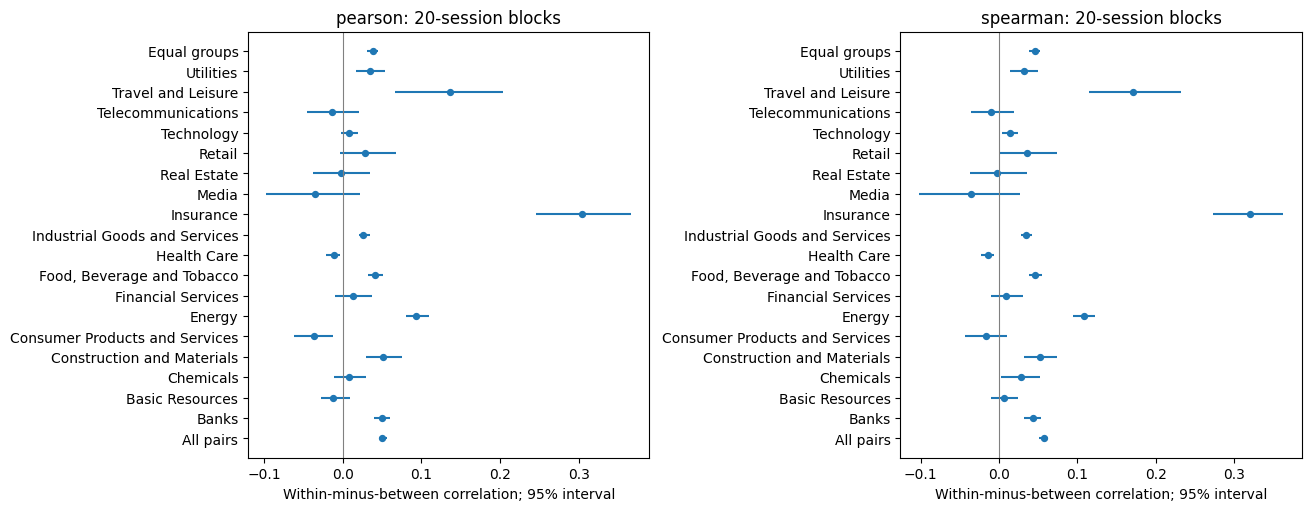

In [8]:
upper_i, upper_j = np.triu_indices(len(stock_ids), 1)
pair_order = pair_tables["Complete dates"]
known_pair = pair_order["known_sectors"].to_numpy()
same_pair = pair_order["same_sector"].to_numpy()
sector_names = sorted(selected["sector"].dropna().unique())
group_masks = {"All pairs": (known_pair & same_pair, known_pair & ~same_pair)}
for sector in sector_names:
    a = pair_order["sector_i"].eq(sector).to_numpy()
    b = pair_order["sector_j"].eq(sector).to_numpy()
    group_masks[sector] = (known_pair & a & b, known_pair & (a ^ b))


def correlation_array(values: np.ndarray) -> np.ndarray:
    """Pearson matrix with undefined constant-series entries left missing."""
    centered = values - values.mean(axis=0)
    norms = np.sqrt((centered ** 2).sum(axis=0))
    denominator = norms[:, None] * norms[None, :]
    return np.divide(centered.T @ centered, denominator,
                     out=np.full(denominator.shape, np.nan), where=denominator > 0)


def correlation_differences(values: np.ndarray) -> np.ndarray:
    """Global, per-sector, and equal-sector within-minus-between differences."""
    rows = []
    for sample in [values, stats.rankdata(values, axis=0, method="average")]:
        correlations = correlation_array(sample)[upper_i, upper_j]
        differences = []
        for inside, outside in group_masks.values():
            x, y = correlations[inside], correlations[outside]
            differences.append(np.nanmean(x) - np.nanmean(y) if len(x) and len(y) else np.nan)
        differences.append(np.nanmean(differences[1:]))
        rows.append(differences)
    return np.asarray(rows)


def bootstrap_differences(frame: pd.DataFrame, block: int, draws: int, seed: int) -> np.ndarray:
    """Resample full-grid circular blocks, then retain complete sampled observations."""
    rng = np.random.default_rng(seed)
    values = frame.to_numpy()
    result = np.full((draws, 2, len(group_masks) + 1), np.nan)
    with threadpool_limits(limits=1):
        for draw in range(draws):
            starts = rng.integers(0, len(values), size=int(np.ceil(len(values) / block)))
            indices = ((starts[:, None] + np.arange(block)) % len(values)).ravel()[:len(values)]
            sampled = values[indices]
            sampled = sampled[np.isfinite(sampled).all(axis=1)]
            if len(sampled) >= MIN_PAIR:
                result[draw] = correlation_differences(sampled)
    return result


bootstrap_samples, bootstrap_rows = {}, []
point_differences = correlation_differences(complete.to_numpy())
group_names = [*group_masks, "Equal groups"]
bootstrap_started = perf_counter()
for block in BOOT_BLOCKS:
    draws = bootstrap_differences(returns, block, BOOT_DRAWS, SEED)
    bootstrap_samples[block] = draws
    for m, metric in enumerate(["pearson", "spearman"]):
        for k, group in enumerate(group_names):
            observed = draws[:, m, k]
            observed = observed[np.isfinite(observed)]
            low, high = np.quantile(observed, [0.025, 0.975]) if len(observed) else (np.nan, np.nan)
            bootstrap_rows.append({"block_sessions": block, "metric": metric, "group": group,
                "difference": point_differences[m, k], "lower_95": low, "upper_95": high,
                "valid_draws": len(observed), "requested_draws": BOOT_DRAWS})
    print(f"Bootstrap block {block}: completed {BOOT_DRAWS:,} draws", flush=True)
bootstrap_ci = pd.DataFrame(bootstrap_rows)
print(f"Bootstrap runtime: {perf_counter() - bootstrap_started:.1f} seconds")
display(bootstrap_ci.loc[bootstrap_ci.metric.eq("pearson") & bootstrap_ci.group.isin(["All pairs", "Equal groups"]),
    ["block_sessions", "group", "difference", "lower_95", "upper_95"]].rename(columns={
    "block_sessions": "Block length", "group": "Weighting", "difference": "Gap", "lower_95": "95% lower", "upper_95": "95% upper"}).round(3).reset_index(drop=True))
fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
for ax, metric in zip(axes, ["pearson", "spearman"]):
    table = bootstrap_ci.loc[bootstrap_ci["block_sessions"].eq(20) & bootstrap_ci["metric"].eq(metric)].dropna(subset=["lower_95"])
    ax.hlines(table["group"], table["lower_95"], table["upper_95"])
    ax.scatter(table["difference"], table["group"], s=18)
    ax.axvline(0, color="grey", linewidth=0.8)
    ax.set(title=f"{metric}: 20-session blocks", xlabel="Within-minus-between correlation; 95% interval")
plt.show()
plt.close(fig)

## 5. See how correlation changes over time

**What:** Calculate correlations over the previous **63 sessions (~3 months)** and **252 sessions (~1 year)**.
**Why:** A five-year average can hide temporary spikes or changes.

**First figure:** top = same-group and different-group correlations; middle = their gap;
bottom = contributing pair counts. Each point uses the window ending on that date.
Changing pair counts can affect averages. Early unavailable windows do not mean zero correlation.

**Second figure:** compare returns from −5 to +5 sessions apart. Lag +1 compares stock i today with stock j next session.
The stock order defines i and j. A lagged correlation alone does not establish predictability or causality.

<details>
<summary>Method details and sources</summary>

Rolling windows use consecutive sessions on the original grid. A pair contributes only
when both stocks are observed on every session of that window. Changing contributing
pairs can change averages, so their counts are plotted alongside correlations. The
group gap is unavailable if no within-group or between-group pairs contribute.

For lag \(k\), calculate \(\mathrm{Corr}(r_{i,t},r_{j,t+k})\). Positive \(k\) means
stock \(i\) precedes stock \(j\); zero is contemporaneous. Pair orientation is the
fixed stock-column order. Nonzero-lag results are descriptive, involve many comparisons,
and do not by themselves establish predictability or causality.

</details>


,Median within-group correlation,Median between-group correlation,Median gap
Window (sessions),,,
63,0.107,0.049,0.055
252,0.117,0.062,0.054


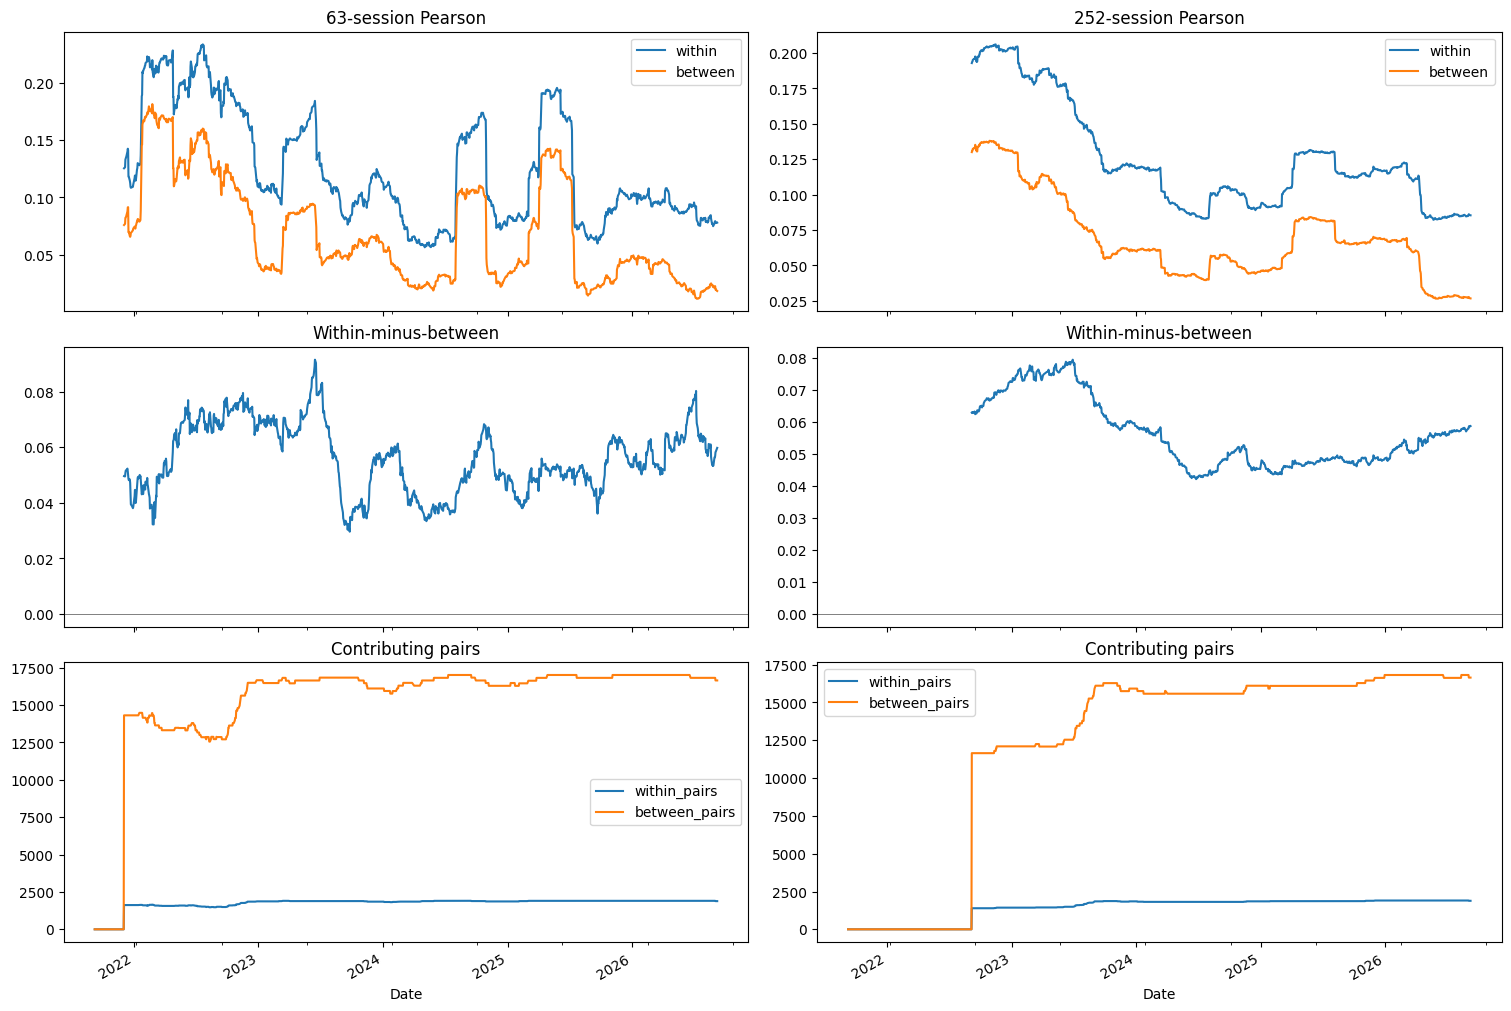

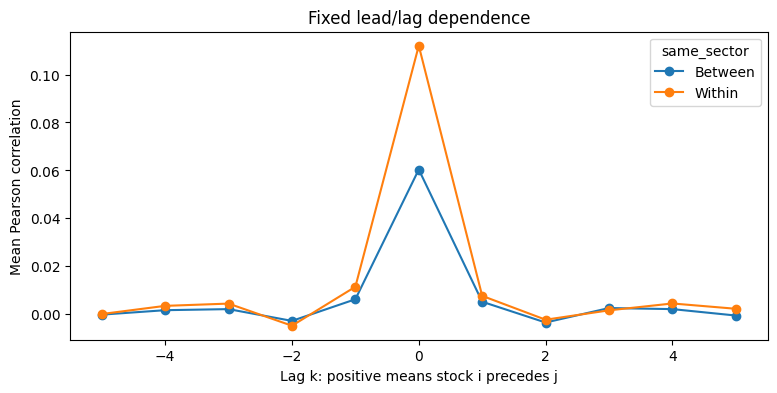

In [9]:
rolling_parts = []
for window in (63, 252):
    internal_sum, external_sum = np.zeros(len(returns)), np.zeros(len(returns))
    internal_n, external_n = np.zeros(len(returns), dtype=int), np.zeros(len(returns), dtype=int)
    for row in pair_tables["Available pairs"].itertuples():
        if not row.known_sectors:
            continue
        a, b = returns[row.stock_i], returns[row.stock_j]
        corr = a.rolling(window, min_periods=window).corr(b).to_numpy()
        valid = (a.notna() & b.notna()).rolling(window, min_periods=window).sum().eq(window).to_numpy()
        valid &= np.isfinite(corr)
        sums, counts = (internal_sum, internal_n) if row.same_sector else (external_sum, external_n)
        sums[valid] += corr[valid]
        counts[valid] += 1
    inside = np.divide(internal_sum, internal_n, out=np.full(len(returns), np.nan), where=internal_n > 0)
    outside = np.divide(external_sum, external_n, out=np.full(len(returns), np.nan), where=external_n > 0)
    rolling_parts.append(pd.DataFrame({"Date": sessions, "window": window, "within": inside,
        "between": outside, "difference": inside - outside,
        "within_pairs": internal_n, "between_pairs": external_n}))
rolling_summary = pd.concat(rolling_parts, ignore_index=True)
display(rolling_summary.groupby("window").agg(
    same_sector=("within", "median"), different_sectors=("between", "median"), gap=("difference", "median")
).rename_axis("Window (sessions)").rename(columns={"same_sector": "Median within-group correlation",
    "different_sectors": "Median between-group correlation", "gap": "Median gap"}).round(3))
fig, axes = plt.subplots(3, 2, figsize=(15, 10), sharex="col", constrained_layout=True)
for col, window in enumerate((63, 252)):
    part = rolling_summary.loc[rolling_summary["window"].eq(window)].set_index("Date")
    part[["within", "between"]].plot(ax=axes[0, col], title=f"{window}-session Pearson")
    part["difference"].plot(ax=axes[1, col], title="Within-minus-between")
    axes[1, col].axhline(0, color="grey", linewidth=0.7)
    part[["within_pairs", "between_pairs"]].plot(ax=axes[2, col], title="Contributing pairs")
plt.show()
plt.close(fig)

lag_parts = []
for lag in range(-5, 6):
    shifted = returns.shift(-lag)
    a, b = returns.to_numpy(), shifted.to_numpy()
    ma, mb = np.isfinite(a).astype(float), np.isfinite(b).astype(float)
    a, b = np.nan_to_num(a), np.nan_to_num(b)
    # Matrix sums use each pair's actual overlapping observations.
    with threadpool_limits(limits=1):
        n = ma.T @ mb
        sx, sy = a.T @ mb, ma.T @ b
        safe_n = np.maximum(n, 1)
        covariance = a.T @ b - sx * sy / safe_n
        vx = (a * a).T @ mb - sx * sx / safe_n
        vy = ma.T @ (b * b) - sy * sy / safe_n
    denominator = np.sqrt(np.maximum(vx, 0) * np.maximum(vy, 0))
    corr = np.divide(covariance, denominator, out=np.full(n.shape, np.nan),
                     where=(n >= MIN_PAIR) & (denominator > 0))
    part = pair_tables["Available pairs"][["stock_i", "stock_j", "known_sectors", "same_sector"]].copy()
    part["lag"], part["n_pair"], part["correlation"] = lag, n[upper_i, upper_j].astype(int), corr[upper_i, upper_j]
    lag_parts.append(part)
lag_pairs = pd.concat(lag_parts, ignore_index=True)
lag_summary = lag_pairs.loc[lag_pairs["known_sectors"]].groupby(["lag", "same_sector"]).agg(
    mean_correlation=("correlation", "mean"), contributing_pairs=("correlation", "count"))
fig, ax = plt.subplots(figsize=(9, 4))
lag_summary["mean_correlation"].unstack("same_sector").rename(columns={False: "Between", True: "Within"}).plot(ax=ax, marker="o")
ax.set(xlabel="Lag k: positive means stock i precedes j", ylabel="Mean Pearson correlation", title="Fixed lead/lag dependence")
plt.show()
plt.close(fig)


### 5a. Look closely at market-shock dates

**What:** Zoom in using **20-session correlations (~1 month)**, with typical daily stock returns below.
**Why:** Connect broad market moves with changes in correlation at a shorter timescale.

**Read each column:** blue = same group; orange = different groups.
Red dashed lines mark selected shock dates. Grey dotted lines show when those dates leave the window.
Bars show the median stock return, not OSEBX. Shared rallies can also raise correlation.

The table compares same-group correlation with and without the marked dates, keeping stocks fixed.
Each window ends on its episode's last marked date. Omitting dates makes the sample shorter;
this is a sensitivity check, not a causal estimate. Short windows are noisier, and contributing pairs can change.

<details>
<summary>Method details and sources</summary>

Each column below links **20-session rolling correlations** (top) with the
**median daily simple return of observed selected stocks** (bottom).
Red dashed lines mark selected shock dates; grey dotted lines mark the sessions
when those observations leave the trailing window. A shock can therefore affect
the estimate for roughly one trading month, even if markets recover sooner. Correlation
cannot be estimated from one day's return pair: the top curves always use windows.
The daily median describes the typical observed stock and limits the influence of
extreme individual returns. It is **not OSEBX**; observed-stock membership varies.
The correlation curves use the same full-window support rule as section 5, now over
20 sessions. Contributing pairs can still change. Shorter windows react faster but
produce noisier estimates, and a few shared extreme returns can dominate them.

The table compares correlations in the 20-session window **ending on the final
highlighted date** of each episode, using the **same stocks** with and without the
highlighted observations. Each original sample has 20 consecutive sessions and no
missing returns in participating stocks. Omitting
shock dates reduces the number of observations; it does not fill gaps or change
the main analysis. `primary_day_down_pct` is the percentage of observed selected
stocks with negative returns on the episode's primary date. These dates were chosen
after inspecting the series: this is a descriptive sensitivity check, not a causal
test or an unbiased estimate of a typical event effect. The smaller late-2023 bump
is omitted because no single dominant shock was isolated.

Historical context checked for these episodes:

- **24 January 2022:** [E24](https://e24.no/boers-og-finans/i/G38JVm/oslo-boers-faller-forsiktig-fra-start)
  reports broad selling, rate concerns and Russia–Ukraine tensions. This date precedes
  the invasion; the 20-session sensitivity window ends on 24 January.
- **13–16 June 2022:** [Norges Bank's June assessment](https://www.norges-bank.no/en/topics/Monetary-policy/Monetary-policy-meetings/2022/june-2022/?tab=122929)
  describes higher inflation, faster expected policy tightening and falling global equities.
- **23–28 September 2022:** [contemporary reporting](https://www.bt.no/nyheter/okonomi/i/8JBjnE/venter-flat-aapning-paa-oslo-boers)
  describes rate and recession fears on 23 September; the
  [government's aquaculture-tax proposal](https://www.regjeringen.no/no/aktuelt/grunnrenteskatt-pa-havbruk/id2929113/)
  was announced on 28 September, when [seafood shares fell sharply](https://www.bt.no/nyheter/okonomi/i/15714X/venter-nedgang-paa-oslo-boers).
- **13–15 March 2023:** [Norges Bank](https://www.norges-bank.no/en/news-events/publications/Financial-Stability-report/2023-1-finansiell-stabilitet/web-report-2023-1-financial-stability/)
  documents the SVB and Credit Suisse turmoil and international market volatility.
- **2–5 August 2024:** [BIS](https://www.bis.org/publications/qr-202409/carry-off-carry-on)
  connects the sell-off to US labour-market news and unwinding leveraged positions.
- **3–10 April 2025:** [Norges Bank](https://www.norges-bank.no/en/news-events/publications/Financial-Stability-report/2025-1-financial-stability/web-report-2025-1-financial-stability/)
  describes tariff announcements, countermeasures and large Norwegian market movements.
- **8 April 2026:** [NTB/Aftenposten](https://www.aftenposten.no/okonomi/i/JOror7/kraftig-fall-paa-oslo-boers-ned-28-prosent)
  reports an Iran ceasefire, falling oil prices and divergent oil-stock/airline reactions.

Event labels describe plausible context; timing and sensitivity alone do not establish
that a named event caused the entire correlation peak. Shared rallies can also raise
correlation, and group-specific shocks need not increase between-group correlation.

</details>


,Episode,Window ends,Stocks,All dates,Without shock dates
0,2022: rate fears and Ukraine tensions,2022-01-24,188,0.311,0.179
1,2022: inflation and rate repricing,2022-06-16,183,0.212,0.110
2,2022: rate fears and salmon-tax proposal,2022-09-28,190,0.234,0.204
3,2023: SVB and Credit Suisse turmoil,2023-03-15,195,0.211,0.109
4,2024: global August sell-off,2024-08-05,195,0.257,0.049
5,2025: tariff shock,2025-04-10,195,0.278,0.125
6,2026: ceasefire and oil-price reversal,2026-04-08,195,0.124,0.101


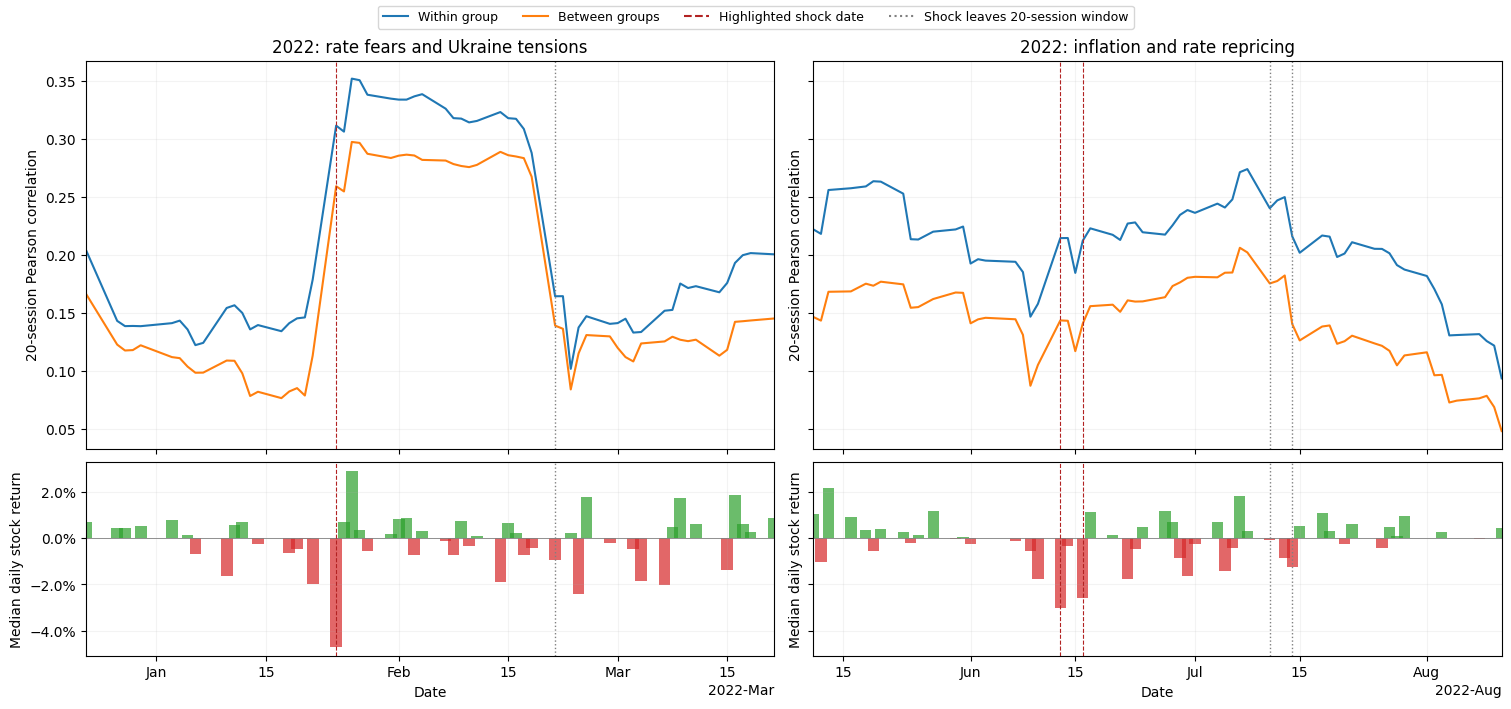

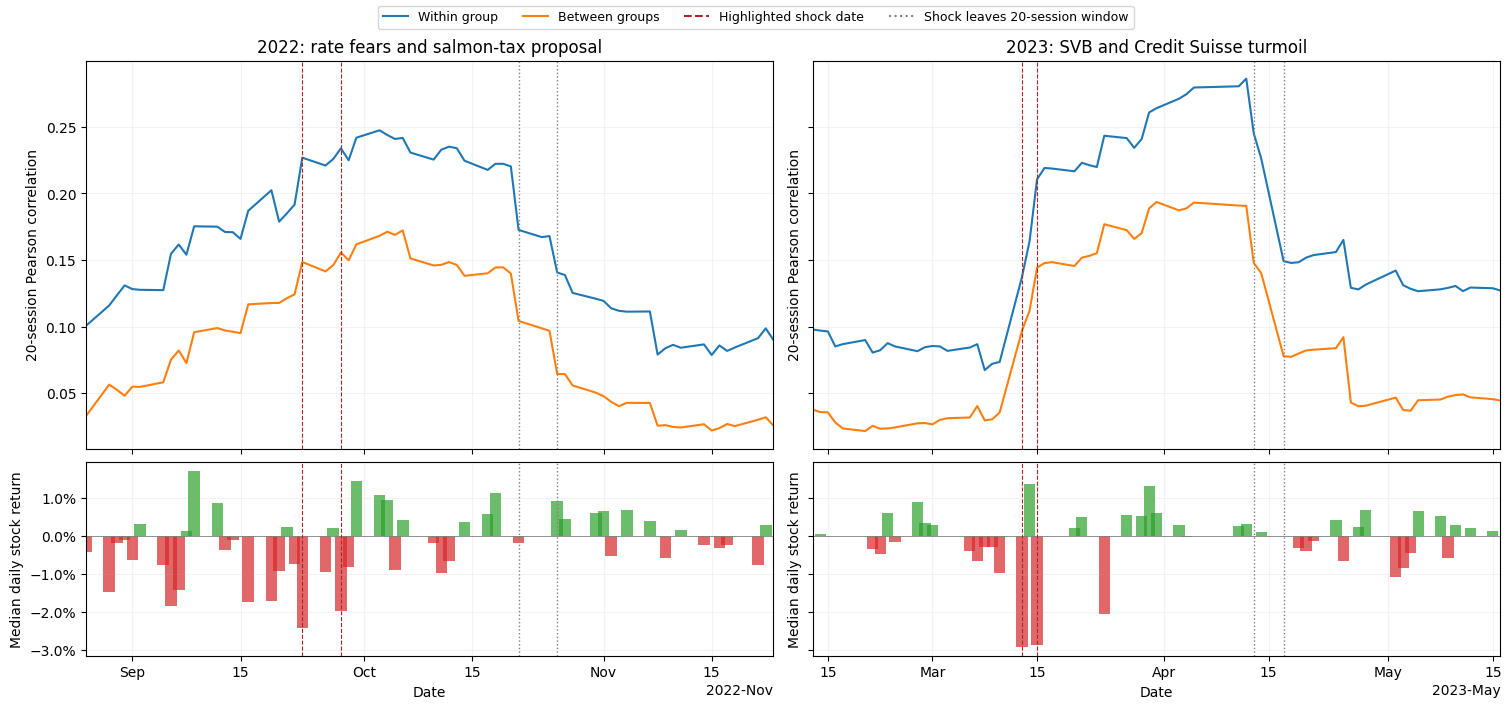

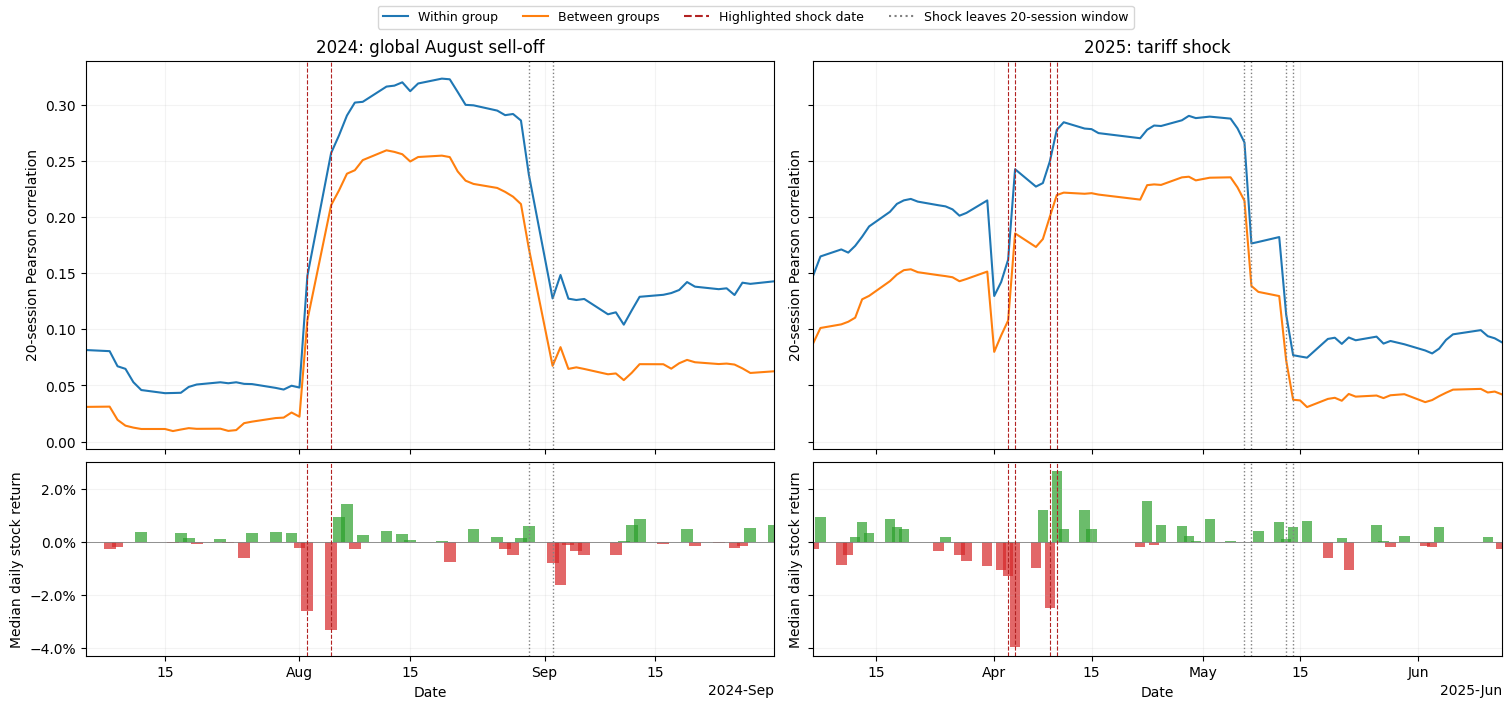

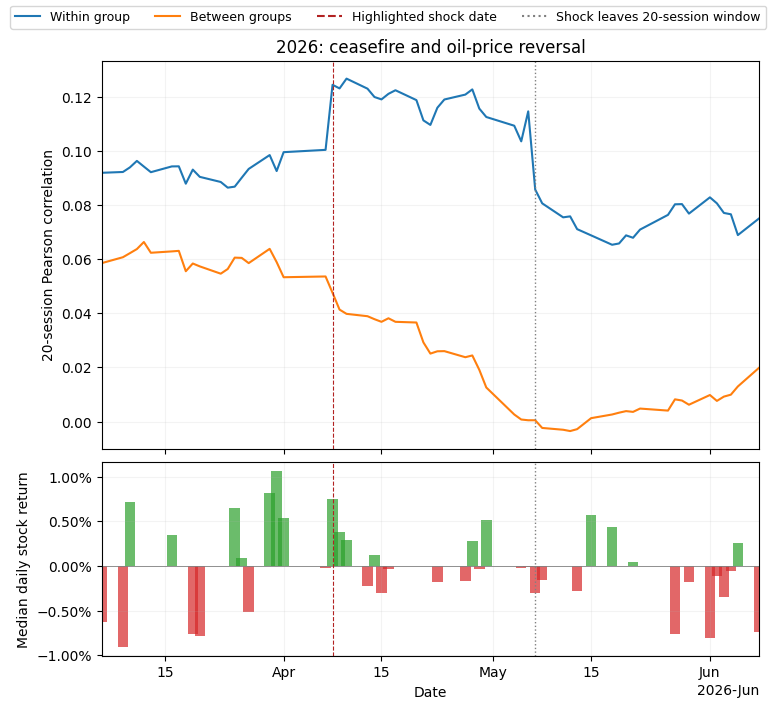

In [10]:
from matplotlib import dates as mdates
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter

# Dates identify historical episodes, not an automatically detected or causal model.
# Sensitivity windows end on the final highlighted date in each episode.
shock_window = 20
shock_events = [
    ("2022: rate fears and Ukraine tensions", "2022-01-24",
     ["2022-01-24"]),
    ("2022: inflation and rate repricing", "2022-06-13",
     ["2022-06-13", "2022-06-16"]),
    ("2022: rate fears and salmon-tax proposal", "2022-09-23",
     ["2022-09-23", "2022-09-28"]),
    ("2023: SVB and Credit Suisse turmoil", "2023-03-13",
     ["2023-03-13", "2023-03-15"]),
    ("2024: global August sell-off", "2024-08-02",
     ["2024-08-02", "2024-08-05"]),
    ("2025: tariff shock", "2025-04-04",
     ["2025-04-03", "2025-04-04", "2025-04-09", "2025-04-10"]),
    ("2026: ceasefire and oil-price reversal", "2026-04-08",
     ["2026-04-08"]),
]
# Median observed-stock return limits the influence of extreme individual returns; not OSEBX.
shock_simple_returns = np.expm1(returns)
shock_daily_median = shock_simple_returns.median(axis=1)
shock_down_fraction = returns.lt(0).sum(axis=1).div(returns.notna().sum(axis=1))


def shock_pair_means(frame: pd.DataFrame) -> tuple[float, float]:
    """Pair-weighted means on the supplied, complete stock sample."""
    corr = frame.corr().to_numpy()
    i, j = np.triu_indices(frame.shape[1], 1)
    sectors = selected.loc[frame.columns, "sector"]
    known = sectors.notna().to_numpy()
    same = sectors.to_numpy()[i] == sectors.to_numpy()[j]
    valid = known[i] & known[j] & np.isfinite(corr[i, j])
    return tuple(corr[i[mask], j[mask]].mean() if mask.any() else np.nan
                 for mask in (valid & same, valid & ~same))


# Apply section 5's full-window support rule at the shorter horizon.
shock_rolling_rows = []
for shock_stop in range(shock_window, len(returns) + 1):
    shock_sample = returns.iloc[shock_stop - shock_window:shock_stop]
    shock_supported = shock_sample.notna().all() & shock_sample.std().gt(0)
    shock_inside, shock_outside = shock_pair_means(shock_sample.loc[:, shock_supported])
    shock_rolling_rows.append({"Date": shock_sample.index[-1],
                               "within": shock_inside, "between": shock_outside})
shock_rolling = pd.DataFrame(shock_rolling_rows).set_index("Date")

shock_rows = []
for shock_title, shock_primary, shock_dates in shock_events:
    shock_dates = pd.DatetimeIndex(shock_dates)
    shock_sample = returns.loc[:shock_dates.max()].iloc[-shock_window:]
    assert len(shock_sample) == shock_window and shock_dates.isin(shock_sample.index).all()
    shock_omitted = shock_sample.drop(index=shock_dates)
    # Hold stocks fixed across both calculations; undefined correlations stay missing.
    shock_supported = (shock_sample.notna().all() & shock_sample.std().gt(0)
                       & shock_omitted.std().gt(0))
    shock_full = shock_pair_means(shock_sample.loc[:, shock_supported])
    shock_without = shock_pair_means(shock_omitted.loc[:, shock_supported])
    shock_rows.append({
        "episode": shock_title, "window_start": shock_sample.index[0].date(),
        "window_end": shock_sample.index[-1].date(),
        "omitted_dates": ", ".join(shock_dates.strftime("%Y-%m-%d")),
        "stocks": int(shock_supported.sum()), "dates_after_omission": len(shock_omitted),
        "within_all": shock_full[0], "within_without_shocks": shock_without[0],
        "between_all": shock_full[1], "between_without_shocks": shock_without[1],
        "primary_day_down_pct": 100 * shock_down_fraction.loc[shock_primary],
    })
shock_summary = pd.DataFrame(shock_rows)
display(shock_summary[["episode", "window_end", "stocks", "within_all", "within_without_shocks"]].rename(columns={
    "episode": "Episode", "window_end": "Window ends", "stocks": "Stocks", "within_all": "All dates",
    "within_without_shocks": "Without shock dates"}).round(3))

# Two episodes per figure: correlation above, median daily stock return below.
for shock_offset in range(0, len(shock_events), 2):
    shock_batch = shock_events[shock_offset:shock_offset + 2]
    fig, shock_axes = plt.subplots(2, len(shock_batch), figsize=(7.5 * len(shock_batch), 7),
                                  squeeze=False, sharex="col",
                                  sharey="row", constrained_layout=True,
                                  gridspec_kw={"height_ratios": [2, 1]})
    for shock_col, (shock_title, shock_primary, shock_dates) in enumerate(
        shock_batch
    ):
        shock_dates = pd.DatetimeIndex(shock_dates)
        shock_positions = returns.index.get_indexer(shock_dates)
        # An observation leaves the trailing window after shock_window sessions.
        shock_exits = returns.index[shock_positions + shock_window]
        shock_left = max(0, shock_positions.min() - 20)
        shock_right = min(len(returns), shock_positions.max() + shock_window + 21)
        shock_index = returns.index[shock_left:shock_right]
        shock_view = shock_rolling.reindex(shock_index)
        shock_ax, shock_return_ax = shock_axes[:, shock_col]
        shock_ax.plot(shock_index, shock_view["within"], color="tab:blue", label="Within group")
        shock_ax.plot(shock_index, shock_view["between"], color="tab:orange", label="Between groups")
        shock_ax.set(title=shock_title, ylabel=f"{shock_window}-session Pearson correlation")
        shock_values = shock_daily_median.reindex(shock_index)
        shock_return_ax.bar(shock_index, shock_values, width=1.5,
                            color=np.where(shock_values.lt(0), "tab:red", "tab:green"), alpha=0.7)
        shock_return_ax.axhline(0, color="grey", linewidth=0.6)
        shock_return_ax.set(ylabel="Median daily stock return", xlabel="Date")
        shock_return_ax.yaxis.set_major_formatter(PercentFormatter(1))
        for shock_axis in (shock_ax, shock_return_ax):
            for shock_date in shock_dates:
                shock_axis.axvline(shock_date, color="firebrick", linestyle="--", linewidth=0.8)
            for shock_exit in shock_exits:
                shock_axis.axvline(shock_exit, color="grey", linestyle=":", linewidth=1)
            shock_axis.set_xlim(shock_index[0], shock_index[-1])
            shock_axis.grid(alpha=0.15)
        shock_locator = mdates.AutoDateLocator(minticks=4, maxticks=7)
        shock_return_ax.xaxis.set_major_locator(shock_locator)
        shock_return_ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(shock_locator))
        shock_handles, _ = shock_ax.get_legend_handles_labels()
        shock_legend_handles = shock_handles + [
            Line2D([], [], color="firebrick", linestyle="--", label="Highlighted shock date"),
            Line2D([], [], color="grey", linestyle=":", label=f"Shock leaves {shock_window}-session window"),
        ]
    fig.legend(handles=shock_legend_handles, loc="outside upper center", ncol=4, fontsize=9)
    plt.show()
    plt.close(fig)



## 6. Remove broad market movement

**What:** Fit each stock's return against the average return of the other stocks.
Then compare the leftover returns, called **residuals**.
**Why:** Group peers might move together simply because the whole market moves together.

**Read the results:** compare the group gap before and after adjustment.
A remaining positive gap means this particular market proxy does not explain all the group structure.

<details>
<summary>Method details and sources</summary>

For each stock, convert other stocks' calculated log returns to simple returns, average
them equally, then use `log1p` of that average as the explanatory return. Excluding the
target stock avoids its direct inclusion in its own proxy. Fit an intercept and slope
by ordinary least squares on the complete-date panel, and compare residual correlations.

This is a contemporaneous descriptive adjustment using a selected-universe proxy,
**not OSEBX, a CAPM test, or an out-of-sample forecast**. Each stock has a slightly
different leave-one-out proxy. Residual group structure depends on this proxy choice.

</details>


,Same group,Different groups,Gap
Result,,,
Before adjustment,0.100,0.050,0.050
After adjustment,0.082,0.036,0.046


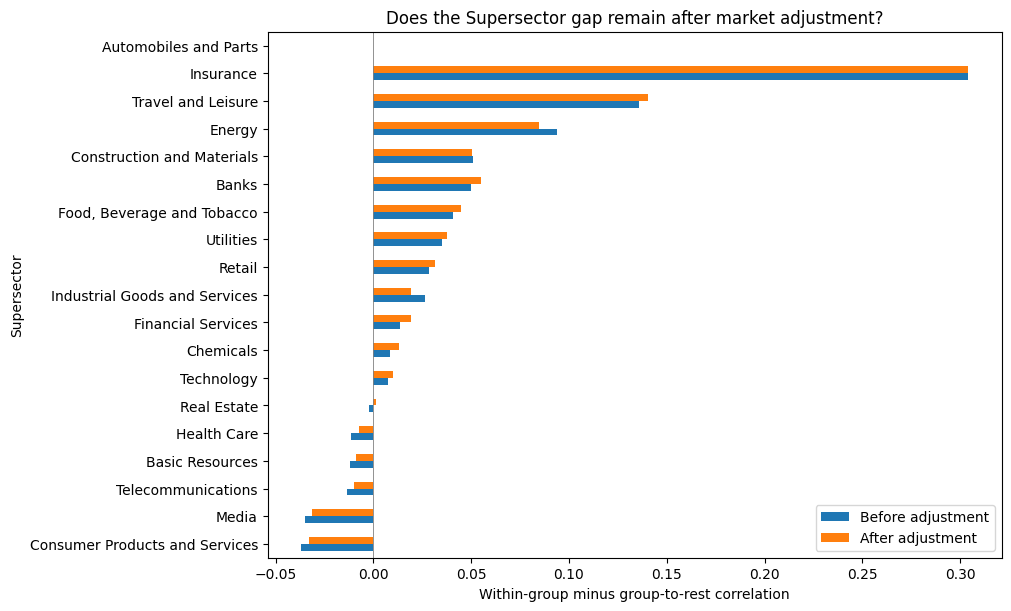

In [11]:
simple = np.expm1(complete)
proxy_simple = (simple.sum(axis=1).to_numpy()[:, None] - simple.to_numpy()) / (len(stock_ids) - 1)
market_proxies = pd.DataFrame(np.log1p(proxy_simple), index=complete.index, columns=stock_ids)
residuals = pd.DataFrame(index=complete.index, columns=stock_ids, dtype=float)
regression_rows = []
for stock_id in stock_ids:
    design = np.column_stack([np.ones(len(complete)), market_proxies[stock_id]])
    coefficients = np.linalg.lstsq(design, complete[stock_id].to_numpy(), rcond=None)[0]
    residuals[stock_id] = complete[stock_id] - design @ coefficients
    regression_rows.append({"stock_id": stock_id, "name": selected.loc[stock_id, "name"],
                            "alpha": coefficients[0], "beta": coefficients[1],
                            "r_squared": 1 - residuals[stock_id].var() / complete[stock_id].var()})
regressions = pd.DataFrame(regression_rows).set_index("stock_id")
residual_matrices, residual_pairs = dependence_pairs(residuals, absolute=False)
residual_global, residual_sectors = sector_summaries(residual_pairs, ["pearson", "spearman"], "Proxy residuals; complete dates")
raw_market_comparison = global_comparison.loc[global_comparison.panel.eq("Complete dates")
    & global_comparison.metric.eq("pearson") & global_comparison.weighting.eq("pairs")]
adjusted_market_comparison = residual_global.loc[residual_global.metric.eq("pearson") & residual_global.weighting.eq("pairs")]
market_comparison = pd.concat([raw_market_comparison.assign(Result="Before adjustment"), adjusted_market_comparison.assign(Result="After adjustment")])
display(market_comparison.set_index("Result")[["within_mean", "between_mean", "difference"]].rename(columns={
    "within_mean": "Same group", "between_mean": "Different groups", "difference": "Gap"}).round(3))
market_sector_chart = pd.DataFrame({
    "Before adjustment": sector_comparison.loc[sector_comparison.panel.eq("Complete dates") & sector_comparison.metric.eq("pearson")].set_index("sector")["difference"],
    "After adjustment": residual_sectors.loc[residual_sectors.metric.eq("pearson")].set_index("sector")["difference"],
}).sort_values("Before adjustment")
fig, ax = plt.subplots(figsize=(10, 6), constrained_layout=True)
market_sector_chart.plot.barh(ax=ax)
ax.axvline(0, color="grey", linewidth=0.6)
ax.set(title=f"Does the {GROUPING_LEVEL} gap remain after market adjustment?", xlabel="Within-group minus group-to-rest correlation", ylabel=GROUPING_LEVEL)
plt.show()
plt.close(fig)


## 7. Check whether bad days happen together

**What:** Identify each stock's worst roughly 5% of returns.
Ask: **when one stock has a bad day, how often does its partner also have a bad day?**
**Why:** Average correlation can miss shared extreme losses.

The table compares that conditional frequency within groups and across groups, averaging both directions per pair.
It is not the chance that both stocks have a bad day on a randomly chosen date.

<details>
<summary>Method details and sources</summary>

Within each pair-aligned sample, average-rank pseudo-observations are `rank/(n+1)`.
An observation is in the lower tail when its pseudo-observation is at most 0.05.
Ties can change the realised marginal event rates. At least 1,000 paired observations
and 20 events in the conditioning stock are required for a conditional estimate.

The independence reference is the product of the **observed** marginal tail frequencies.
These are finite-threshold co-loss frequencies, not asymptotic tail-dependence estimates.
The smaller complete-date panel may be too short; unavailable values remain blank.

</details>


In [12]:
def tail_metrics(x: np.ndarray, y: np.ndarray) -> dict:
    """Estimate rank-tail co-losses with explicit support and conditioning thresholds."""
    valid = np.isfinite(x) & np.isfinite(y)
    x, y = x[valid], y[valid]
    n = len(x)
    out = dict(n_pair=n, tail_n_i=np.nan, tail_n_j=np.nan, joint_count=np.nan,
               joint_probability=np.nan, independence_reference=np.nan,
               conditional_i_given_j=np.nan, conditional_j_given_i=np.nan,
               status="insufficient overlap")
    if n < MIN_TAIL:
        return out
    if np.ptp(x) == 0 or np.ptp(y) == 0:
        out["status"] = "constant series"
        return out
    a = stats.rankdata(x, method="average") / (n + 1) <= TAIL_LEVEL
    b = stats.rankdata(y, method="average") / (n + 1) <= TAIL_LEVEL
    ni, nj, joint = int(a.sum()), int(b.sum()), int((a & b).sum())
    out.update(tail_n_i=ni, tail_n_j=nj, joint_count=joint, joint_probability=joint / n,
               independence_reference=(ni / n) * (nj / n),
               conditional_i_given_j=joint / nj if nj >= MIN_TAIL_EVENTS else np.nan,
               conditional_j_given_i=joint / ni if ni >= MIN_TAIL_EVENTS else np.nan,
               status="available" if min(ni, nj) >= MIN_TAIL_EVENTS else "too few conditioning events")
    return out


tail_parts = []
for label, frame in [("Available pairs", returns), ("Complete dates", complete)]:
    rows = []
    for pair in pair_tables[label].itertuples():
        rows.append({"panel": label, "stock_i": pair.stock_i, "stock_j": pair.stock_j,
                     "name_i": pair.name_i, "name_j": pair.name_j,
                     "known_sectors": pair.known_sectors, "same_sector": pair.same_sector,
                     "sector_i": pair.sector_i, "sector_j": pair.sector_j,
                     "first_date": pair.first_date, "last_date": pair.last_date,
                     **tail_metrics(frame[pair.stock_i].to_numpy(), frame[pair.stock_j].to_numpy())})
    tail_parts.append(pd.DataFrame(rows))
tail_pairs = pd.concat(tail_parts, ignore_index=True)
tail_pairs["joint_excess_over_independence"] = tail_pairs["joint_probability"] - tail_pairs["independence_reference"]
# Symmetric summary; retain both directional conditionals in tail_pairs.
tail_pairs["mean_conditional_coloss"] = tail_pairs[["conditional_i_given_j", "conditional_j_given_i"]].mean(axis=1, skipna=False)
tail_sector_parts = []
for label, part in tail_pairs.groupby("panel", sort=False):
    g, s = sector_summaries(part, ["joint_probability", "joint_excess_over_independence", "mean_conditional_coloss"], label)
    tail_sector_parts.extend([g.assign(summary="global"), s.assign(summary="sector")])
tail_sector_summary = pd.concat(tail_sector_parts, ignore_index=True)
tail_display = tail_pairs.loc[tail_pairs.panel.eq("Available pairs") & tail_pairs.known_sectors].groupby("same_sector").agg(
    conditional_frequency=("mean_conditional_coloss", "mean"), supported_pairs=("mean_conditional_coloss", "count"))
tail_display["conditional_frequency"] *= 100
display(tail_display.rename(index={False: "Different groups", True: "Same group"}).rename_axis("Pair type").rename(columns={
    "conditional_frequency": "Partner also has a bad day (%)", "supported_pairs": "Supported pairs"}).round(1))
if len(complete) < MIN_TAIL:
    print(f"Shared-date sample: {len(complete)} observations; at least {MIN_TAIL} are required for this check.")

,Partner also has a bad day (%),Supported pairs
Pair type,,
Different groups,9.7,17008
Same group,12.7,1907


Shared-date sample: 871 observations; at least 1000 are required for this check.


## 8. Find the main shared patterns (PCA)

**What:** Find weighted combinations of stocks that capture as much return variation as possible.
**Why:** Check whether a few common patterns describe most of the dataset.
We first give each stock equal variance so volatile stocks do not dominate just because of their scale.

**Read the plots:** left = variation explained by each pattern; right = total explained as patterns are added.
The dashed line marks 80%. These patterns are not necessarily independent economic factors.

<details>
<summary>Method details and sources</summary>

Centre and scale each stock by its complete-sample mean and sample standard deviation.
PCA on these data corresponds to the sample correlation matrix, avoiding domination
solely by stocks with larger volatility. Explained-variance shares describe empirical
linear common variation in this selected panel; they do not prove independence of the
remaining components or identify a true number of economic factors.

</details>


,Result
Variation explained by first pattern,8.2%
Variation explained by first five,16.4%
Patterns needed for 80% of variation,108


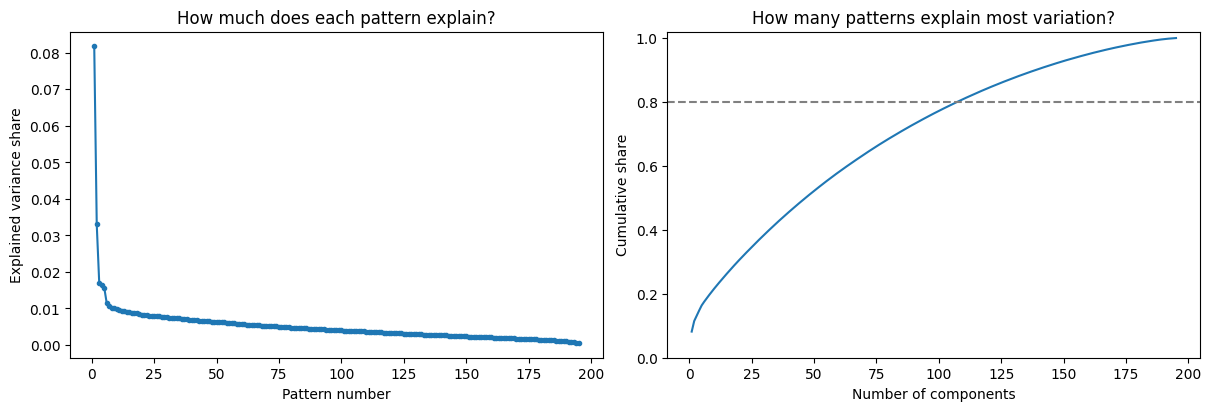

In [13]:
standardised = (complete - complete.mean()) / complete.std(ddof=1)
pca = PCA(svd_solver="full").fit(standardised)
explained = pca.explained_variance_ratio_
cumulative = explained.cumsum()
pca_summary = pd.Series({"stocks": len(stock_ids), "complete_dates": len(complete),
    "first_component_share": explained[0], "first_five_share": explained[:5].sum(),
    "components_for_80pct": int(np.searchsorted(cumulative, 0.80) + 1)}, name="PCA").to_frame()
display(pd.DataFrame({"Result": [f"{explained[0]:.1%}", f"{explained[:5].sum():.1%}", str(int(np.searchsorted(cumulative, .8) + 1))]},
    index=["Variation explained by first pattern", "Variation explained by first five", "Patterns needed for 80% of variation"]))
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
axes[0].plot(np.arange(1, len(explained) + 1), explained, marker=".")
axes[0].set(title="How much does each pattern explain?", xlabel="Pattern number", ylabel="Explained variance share")
axes[1].plot(np.arange(1, len(explained) + 1), cumulative)
axes[1].axhline(0.8, color="grey", linestyle="--")
axes[1].set(title="How many patterns explain most variation?", xlabel="Number of components", ylabel="Cumulative share", ylim=(0, 1.02))
plt.show()
plt.close(fig)

## 9. Compare return shapes with small timing shifts (DTW)

**What:** Compare 20-session return sequences, allowing movements to line up up to two sessions apart.
**Why:** Two stocks may follow similar patterns with slightly different timing.
This asks a different question from same-day correlation.

**Read the results:** smaller distance means more similar shapes.
Each stock/window is scaled first, removing differences in average return and volatility.

<details>
<summary>Method details and sources</summary>

[DTW](https://tslearn.readthedocs.io/en/stable/user_guide/dtw.html) compares paths after
allowing their observations to align at different times. This answers a different
question from simultaneous daily co-movement. It is a distance, not correlation or
direct evidence of diversification.

Partition the original session grid into nonoverlapping 20-return windows. A stock
participates only if all 20 returns are finite and its window variance is positive.
Standardising **within each stock/window** removes level and volatility differences;
the comparison concerns shape. Use a Sakoe–Chiba radius of two sessions and compare
with Euclidean distance on the exact same standardised windows. Both costs are divided
by \(\sqrt{20}\); this is fixed-window scaling, not alignment-path-length normalisation.
At least ten jointly supported windows are required for an aggregate pair distance.

The first two usable windows are benchmarked and their results reused. Numba compilation
can make the first benchmark slower. No windows are sampled or omitted to shorten runtime.

</details>


Compared 62 windows; 18,915 supported stock pairs (14.7s).


,Comparison,Same group,Different groups,Distance gap
0,With timing alignment,0.898,0.921,-0.023
1,Without timing alignment,1.276,1.320,-0.045


Five pairs with the most similar aligned return shapes:


,Stock A,Stock B,Distance,Joint windows
0,AUSTEVOLL SEAFOOD,LERØY SEAFOOD GP,0.479,62
1,AKER BP,EQUINOR,0.528,62
2,MOWI,SALMAR,0.558,62
3,FRONTLINE,OKEANIS ECO TANKER,0.581,62
4,SPAREBANK 1 SMN,SPAREBANK 1 SØR-NO,0.587,62


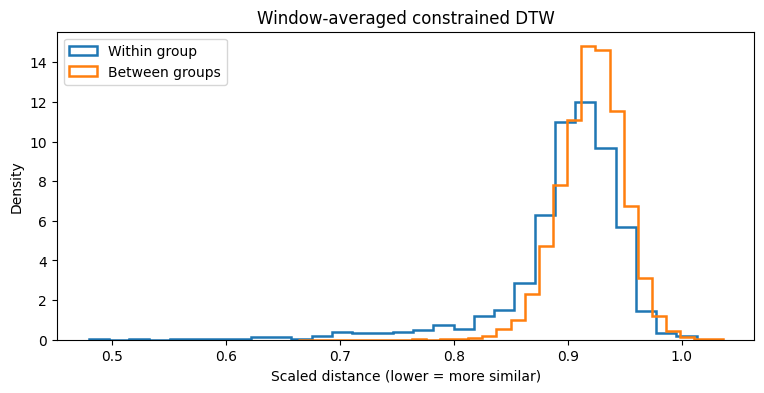

In [14]:
def standardise_window(values: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """Keep only finite, varying stock windows and standardise each independently."""
    finite = np.isfinite(values).all(axis=0)
    indices = np.flatnonzero(finite)
    std = values[:, indices].std(axis=0, ddof=1)
    indices = indices[std > 0]
    sample = values[:, indices].T
    z = (sample - sample.mean(axis=1, keepdims=True)) / sample.std(axis=1, ddof=1, keepdims=True)
    return indices, z


def window_distances(z: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """Calculate constrained DTW and unwarped costs on identical window inputs."""
    warped = cdist_dtw(z[:, :, None], global_constraint="sakoe_chiba",
                       sakoe_chiba_radius=DTW_RADIUS, n_jobs=1, be="numpy") / np.sqrt(WINDOW)
    euclidean = squareform(pdist(z, metric="euclidean")) / np.sqrt(WINDOW)
    return warped, euclidean


dtw_sum = np.zeros((len(stock_ids), len(stock_ids)))
euclidean_sum = np.zeros_like(dtw_sum)
window_counts = np.zeros_like(dtw_sum, dtype=int)
window_audit_rows, distance_benchmarks = [], []
dtw_example_windows = {}
dtw_started = perf_counter()
benchmarked = 0
for window_number, offset in enumerate(range(0, len(returns) - WINDOW + 1, WINDOW)):
    part = returns.iloc[offset:offset + WINDOW]
    indices, z = standardise_window(part.to_numpy())
    window_audit_rows.append({"window": window_number, "start": part.index[0], "end": part.index[-1],
                              "supported_stocks": len(indices), "supported_pairs": len(indices) * (len(indices) - 1) // 2})
    if len(indices) < 2:
        continue
    tick = perf_counter()
    warped, euclidean = window_distances(z)
    assert np.all(warped <= euclidean + 1e-9)
    if benchmarked < 2:
        distance_benchmarks.append({"window": window_number, "stocks": len(indices),
                                    "pairs": len(indices) * (len(indices) - 1) // 2,
                                    "seconds": perf_counter() - tick})
        benchmarked += 1
    ix = np.ix_(indices, indices)
    dtw_sum[ix] += warped
    euclidean_sum[ix] += euclidean
    window_counts[ix] += 1
    # Retain inputs for alignment examples without recomputing the full distance matrices.
    dtw_example_windows[window_number] = (indices, z)
dtw_seconds = perf_counter() - dtw_started
window_audit = pd.DataFrame(window_audit_rows)
dtw_rows = []
for k, (i, j) in enumerate(zip(upper_i, upper_j)):
    n = window_counts[i, j]
    row = pair_tables["Available pairs"].iloc[k][["stock_i", "stock_j", "name_i", "name_j", "sector_i", "sector_j", "known_sectors", "same_sector"]].to_dict()
    row.update(windows=int(n), dtw_mean=dtw_sum[i, j] / n if n >= MIN_DTW_WINDOWS else np.nan,
               euclidean_mean=euclidean_sum[i, j] / n if n >= MIN_DTW_WINDOWS else np.nan)
    dtw_rows.append(row)
dtw_pairs = pd.DataFrame(dtw_rows)
dtw_pairs["warping_reduction"] = dtw_pairs["euclidean_mean"] - dtw_pairs["dtw_mean"]
dtw_global, dtw_sectors = sector_summaries(dtw_pairs, ["dtw_mean", "euclidean_mean", "warping_reduction"], "20-session windows")
print(f"Compared {len(window_audit)} windows; {dtw_pairs.dtw_mean.notna().sum():,} supported stock pairs ({dtw_seconds:.1f}s).")
display(dtw_global.loc[dtw_global.weighting.eq("pairs") & dtw_global.metric.isin(["dtw_mean", "euclidean_mean"]),
    ["metric", "within_mean", "between_mean", "difference"]].replace({"metric": {
    "dtw_mean": "With timing alignment", "euclidean_mean": "Without timing alignment"}}).rename(columns={
    "metric": "Comparison", "within_mean": "Same group", "between_mean": "Different groups", "difference": "Distance gap"}).round(3).reset_index(drop=True))
print("Five pairs with the most similar aligned return shapes:")
display(dtw_pairs.nsmallest(5, "dtw_mean")[["name_i", "name_j", "dtw_mean", "windows"]].rename(columns={
    "name_i": "Stock A", "name_j": "Stock B", "dtw_mean": "Distance", "windows": "Joint windows"}).round(3).reset_index(drop=True))
fig, ax = plt.subplots(figsize=(9, 4))
for same, label in [(True, "Within group"), (False, "Between groups")]:
    values = dtw_pairs.loc[dtw_pairs["known_sectors"] & dtw_pairs["same_sector"].eq(same), "dtw_mean"].dropna()
    ax.hist(values, bins=30, histtype="step", density=True, linewidth=1.8, label=label)
ax.set(title="Window-averaged constrained DTW", xlabel="Scaled distance (lower = more similar)", ylabel="Density")
ax.legend()
plt.show()
plt.close(fig)

### Two examples of timing alignment

**What:** Show two selected stock pairs and how DTW matches their days.
**Why:** Make the meaning of timing alignment visible.
On the left are scaled daily returns. On the right, the diagonal means same-day matching;
departures mean different sessions are being matched, within the two-session limit.
These are illustrative windows, not evidence of a forecasting lead.


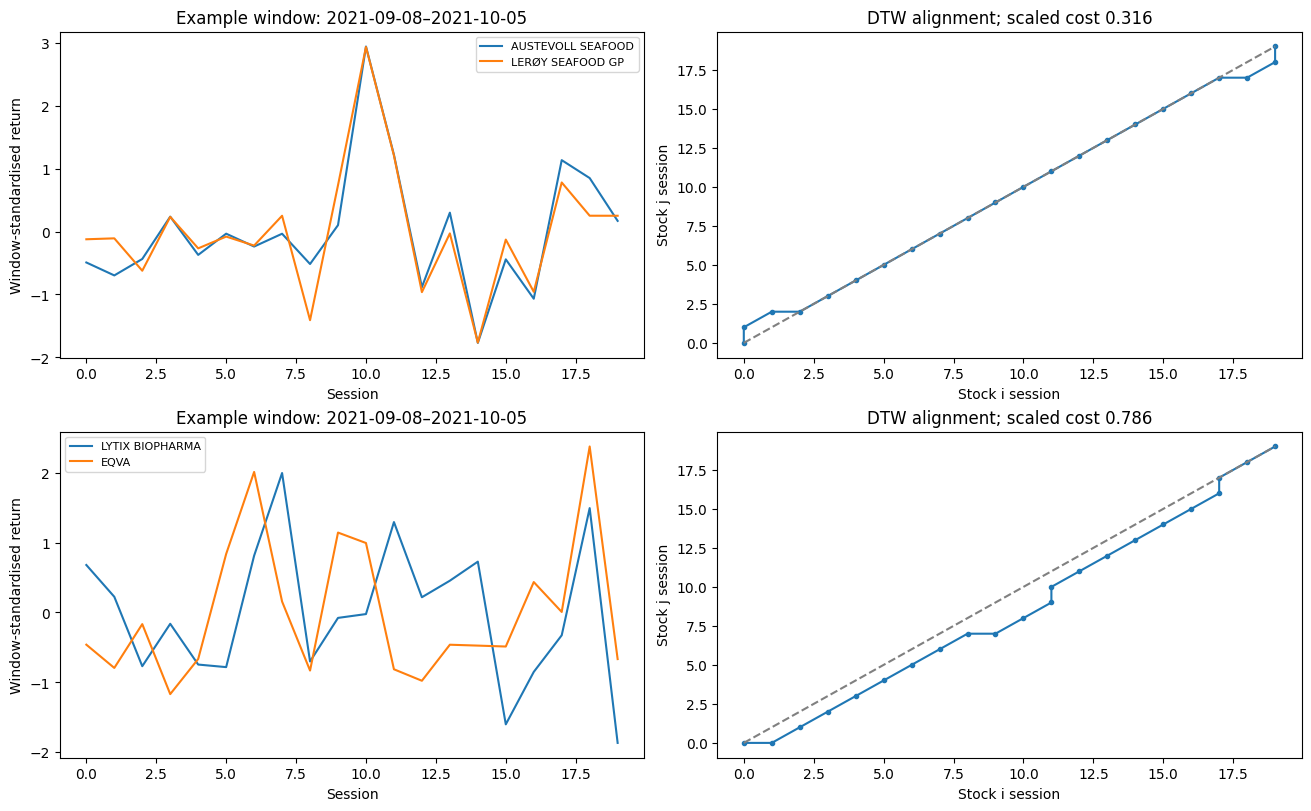

Pairs were chosen by aggregate results; paths show their first jointly supported window.


In [15]:
example_pairs = pd.concat([dtw_pairs.nsmallest(1, "dtw_mean"),
                           dtw_pairs.nlargest(1, "warping_reduction")]).drop_duplicates(["stock_i", "stock_j"])
fig, axes = plt.subplots(len(example_pairs), 2, figsize=(13, 4 * len(example_pairs)), squeeze=False, constrained_layout=True)
alignment_examples = []
for row_number, pair in enumerate(example_pairs.itertuples()):
    i, j = stock_ids.index(pair.stock_i), stock_ids.index(pair.stock_j)
    for number, (indices, z) in dtw_example_windows.items():
        if i in indices and j in indices:
            x, y = z[np.flatnonzero(indices == i)[0]], z[np.flatnonzero(indices == j)[0]]
            path, cost = dtw_path(x, y, global_constraint="sakoe_chiba", sakoe_chiba_radius=DTW_RADIUS, be="numpy")
            axes[row_number, 0].plot(x, label=pair.name_i)
            axes[row_number, 0].plot(y, label=pair.name_j)
            axes[row_number, 0].legend(fontsize=8)
            info = window_audit.loc[window_audit["window"].eq(number)].iloc[0]
            axes[row_number, 0].set(title=f"Example window: {info.start.date()}–{info.end.date()}", xlabel="Session", ylabel="Window-standardised return")
            path_array = np.asarray(path)
            axes[row_number, 1].plot(path_array[:, 0], path_array[:, 1], marker=".")
            axes[row_number, 1].plot([0, WINDOW - 1], [0, WINDOW - 1], linestyle="--", color="grey")
            axes[row_number, 1].set(title=f"DTW alignment; scaled cost {cost / np.sqrt(WINDOW):.3f}", xlabel="Stock i session", ylabel="Stock j session")
            alignment_examples.append({"stock_i": pair.stock_i, "stock_j": pair.stock_j,
                                       "window": number, "cost": cost / np.sqrt(WINDOW)})
            break
plt.show()
plt.close(fig)
print("Pairs were chosen by aggregate results; paths show their first jointly supported window.")

## 10. Check that the calculations behave as intended

**What:** Check stock selection, gaps, correlations, event counts, lag direction, and DTW.
**Why:** Catch coding errors and verify simple cases where we know the expected answer.
Passing these checks does not independently verify the vendor's prices or company identities.

<details>
<summary>Method details and sources</summary>

These checks verify the actual selection and analytical invariants, and use synthetic
examples for gaps, duplicate conflicts, rank ties, lag orientation, and DTW constraints.
The bootstrap reproducibility check repeats a small prefix of the same seeded algorithm,
not an additional full analysis. No claimed validation below is a model fit or proof
that the vendor's adjusted prices and security identities are economically correct.

</details>


In [16]:
# Identity continuity and simultaneous-class separation.
for name, isins in explicit.items():
    assert len({stock_for_isin[i] for i in isins}) == 1, name
for members in {tuple(sorted(m)) for m in history.values()}:
    spans = profiles.loc[list(members)].sort_values("first")
    assert spans["first"].iloc[1:].reset_index(drop=True).gt(spans["last"].iloc[:-1].reset_index(drop=True)).all()
for a, b in [("NO0010571698", "NO0010576010"), ("NO0003399909", "NO0003399917")]:
    assert stock_for_isin[a] != stock_for_isin[b]
assert selected["issuer_key"].is_unique
for key, group in ranked.groupby("issuer_key"):
    assert selected.loc[selected["issuer_key"].eq(key)].index[0] == group.index[0]
assert audit["coverage_eligible"].equals(audit["boundary_ok"] & audit["available_prices"].ge(np.ceil(COVERAGE * len(sessions))))
assert audit["missing_prices"].eq(audit["absent_records"] + audit["recorded_unavailable_prices"]).all()
assert int(audit["selected"].sum()) == len(selected) == funnel.iloc[-1, 0]
assert complete.shape == (int(complete_mask.sum()), len(selected))
assert not complete.isna().any().any()
assert not clean.index.duplicated().any()
assert clean.loc[clean["price_conflict"], "price"].isna().all()
assert all_returns.where(all_prices.loc[sessions].isna() | all_prices.shift().loc[sessions].isna()).isna().all().all()
gap_prices = pd.Series([100., 110., np.nan, 121., 110.])
gap_returns = np.log(gap_prices).diff()
assert pd.isna(gap_returns.iloc[2]) and pd.isna(gap_returns.iloc[3])
assert np.isclose(gap_returns.iloc[1], np.log(1.1))
duplicate_fixture = pd.DataFrame({"date": [0, 0, 1, 1, 2, 2], "price": [100., 100., 110., 120., np.nan, 130.]})
assert duplicate_fixture.groupby("date")["price"].nunique(dropna=False).tolist() == [1, 2, 2]

# Grouping changes labels and ordering, never eligibility or financial observations.
assert stock_ids == stock_ids_before_grouping
assert set(stock_ids) == selected_ids_before_grouping
assert group_counts["Stocks"].sum() == len(selected)
assert int(pair_tables["Complete dates"]["same_sector"].sum()) == int(group_counts["Possible within-group pairs"].sum())
singleton_rows = sector_comparison.loc[sector_comparison["stocks"].eq(1)]
assert singleton_rows["within_pairs"].eq(0).all()
assert singleton_rows["within_mean"].isna().all() and singleton_rows["difference"].isna().all()
if GROUPING_LEVEL != "Original":
    assert selected["sector"].eq(grouping_mapping.loc[stock_ids, f"icb_{GROUPING_LEVEL.lower()}_name"]).all()
# Correlations, sample support, sector pair counts, and covariance matrices.
x = np.arange(1000, dtype=float)
fixture = pd.DataFrame({"x": x, "same": x, "opposite": -x, "constant": 1.})
for method in ["pearson", "spearman"]:
    corr = fixture.corr(method=method)
    assert np.isclose(corr.loc["x", "same"], 1) and np.isclose(corr.loc["x", "opposite"], -1)
    assert pd.isna(corr.loc["x", "constant"])
for panel, pairs in pair_tables.items():
    assert len(pairs) == len(stock_ids) * (len(stock_ids) - 1) // 2
    assert not pairs.duplicated(["stock_i", "stock_j"]).any()
    assert pairs["stock_i"].ne(pairs["stock_j"]).all()
    for metric in ["pearson", "spearman", "absolute"]:
        assert pairs[metric].dropna().between(-1 - 1e-10, 1 + 1e-10).all()
        assert pairs.loc[pairs["n_pair"].lt(MIN_PAIR), metric].isna().all()
        observed = sector_comparison.loc[sector_comparison["panel"].eq(panel) & sector_comparison["metric"].eq(metric), "within_pairs"].sum()
        assert observed == pairs.loc[pairs["same_sector"], metric].count()
for covariance in [sample_covariances["Complete dates"], shrinkage_covariance]:
    assert np.allclose(covariance, covariance.T)
    assert np.linalg.eigvalsh(covariance).min() >= -1e-10
assert np.allclose(residuals.mean(), 0, atol=1e-12)
assert np.allclose((residuals * market_proxies).mean(), 0, atol=1e-12)
assert np.isclose(explained.sum(), 1)

# Tail thresholds, ties, and directional conditioning.
t = tail_metrics(x, x)
assert t["joint_count"] == 50 and t["conditional_i_given_j"] == 1
assert np.isclose(t["joint_probability"], 0.05) and np.isclose(t["independence_reference"], 0.0025)
assert np.isnan(tail_metrics(x[:999], x[:999])["joint_probability"])
assert tail_metrics(np.ones(1000), x)["status"] == "constant series"
assert tail_metrics(np.repeat(np.arange(100), 10), np.repeat(np.arange(100), 10))["conditional_i_given_j"] == 1
for metric in ["joint_probability", "independence_reference", "conditional_i_given_j", "conditional_j_given_i"]:
    assert tail_pairs[metric].dropna().between(0, 1).all()
assert tail_pairs.loc[tail_pairs["tail_n_j"].lt(MIN_TAIL_EVENTS), "conditional_i_given_j"].isna().all()
assert tail_pairs.loc[tail_pairs["tail_n_i"].lt(MIN_TAIL_EVENTS), "conditional_j_given_i"].isna().all()

# Positive lag means i precedes j; shifting does not bridge missing grid sessions.
rng = np.random.default_rng(SEED)
leader = pd.Series(rng.normal(size=500))
follower = leader.shift(2)
assert np.isclose(leader.corr(follower.shift(-2)), 1)
assert abs(leader.corr(follower)) < 0.2
assert np.allclose(lag_pairs.loc[lag_pairs["lag"].eq(0), "correlation"], pair_tables["Available pairs"]["pearson"], equal_nan=True)

# Window validity and DTW limiting cases.
z = rng.normal(size=(2, WINDOW))
diagonal_cost = dtw(z[0], z[1], global_constraint="sakoe_chiba", sakoe_chiba_radius=0, be="numpy")
assert np.isclose(diagonal_cost, np.linalg.norm(z[0] - z[1]))
assert dtw(z[0], z[1], global_constraint="sakoe_chiba", sakoe_chiba_radius=2, be="numpy") <= diagonal_cost + 1e-10
window_fixture = np.column_stack([np.arange(WINDOW, dtype=float), np.ones(WINDOW), np.arange(WINDOW, dtype=float)])
window_fixture[5, 2] = np.nan
indices, _ = standardise_window(window_fixture)
assert indices.tolist() == [0]
assert dtw_pairs.loc[dtw_pairs["windows"].lt(MIN_DTW_WINDOWS), "dtw_mean"].isna().all()
assert (dtw_pairs["dtw_mean"].dropna() >= 0).all()
assert (dtw_pairs["warping_reduction"].dropna() >= -1e-9).all()
assert len(window_audit) == len(returns) // WINDOW
repeat = bootstrap_differences(returns, 20, 3, SEED)
np.testing.assert_allclose(repeat, bootstrap_samples[20][:3], equal_nan=True)
assert np.isfinite(bootstrap_samples[20][:, :, 0]).all()
print("All actual-data and synthetic validation checks passed.")

# Interpolation cannot change raw observations, selection, or an original complete window.
observed_prices_mask = observed_all_prices.notna().to_numpy()
np.testing.assert_array_equal(all_prices.to_numpy()[observed_prices_mask],
                              observed_all_prices.to_numpy()[observed_prices_mask])
observed_returns_mask = observed_all_returns.notna().to_numpy()
np.testing.assert_array_equal(all_returns.to_numpy()[observed_returns_mask],
                              observed_all_returns.to_numpy()[observed_returns_mask])
assert imputed_return_mask.equals(observed_all_returns.isna() & all_returns.notna())
assert audit["missing_prices"].equals(observed_prices_in_window.isna().sum())
assert original_complete_mask.sum() <= complete_mask.sum()
assert returns.loc[original_complete_mask].equals(observed_selected_returns.loc[original_complete_mask])
gap_fixture = pd.DataFrame({"price": [np.nan, 100., np.nan, 102., *([np.nan] * 5),
                                    108., *([np.nan] * 6), 115., 116., np.nan]})
gap_filled, gap_check = interpolate_short_price_gaps(gap_fixture, 5)
assert pd.isna(gap_filled.iloc[0, 0]) and pd.isna(gap_filled.iloc[-1, 0])
assert gap_filled.iloc[2:3, 0].notna().all() and gap_filled.iloc[4:9, 0].notna().all()
assert gap_filled.iloc[10:16, 0].isna().all()
if INTERPOLATE_SHORT_GAPS:
    accepted_gaps = interpolation_gap_audit.loc[interpolation_gap_audit["filled"]]
    assert accepted_gaps["internal"].all() and accepted_gaps["sessions"].le(MAX_INTERPOLATION_GAP).all()
    assert all_prices.where(imputed_price_mask).stack().gt(0).all()
else:
    assert all_prices.equals(observed_all_prices) and all_returns.equals(observed_all_returns)
    assert not imputed_price_mask.any().any() and not imputed_return_mask.any().any()
print("Interpolation, unchanged-observation, and fixed-sample checks passed.")

All actual-data and synthetic validation checks passed.
Interpolation, unchanged-observation, and fixed-sample checks passed.


## 11. Main findings

The table collects the main results calculated above.
**A positive correlation gap means group peers move together more on average.**
For DTW distance, a negative gap means more similar shapes within groups.
These findings describe this selected dataset; low correlation does not prove independence.

<details>
<summary>Method details and sources</summary>

Every numerical statement below is drawn from the executed tables. A positive group
gap indicates higher average internal dependence in this sample; its size, interval,
time variation, and sensitivity to date selection matter more than a binary label.
Lower DTW distances indicate greater similarity, so their group difference has the
opposite interpretation from a correlation difference.

</details>


In [17]:
def global_gap(panel: str, metric: str) -> float:
    """Read the pair-weighted sector gap from the computed comparison table."""
    return float(global_comparison.loc[global_comparison["panel"].eq(panel)
                                       & global_comparison["metric"].eq(metric)
                                       & global_comparison["weighting"].eq("pairs"), "difference"].iloc[0])


primary_ci = bootstrap_ci.loc[bootstrap_ci["block_sessions"].eq(20)
                              & bootstrap_ci["metric"].eq("pearson")
                              & bootstrap_ci["group"].eq("All pairs")].iloc[0]
residual_gap = residual_global.loc[residual_global["metric"].eq("pearson") & residual_global["weighting"].eq("pairs"), "difference"].iloc[0]
tail_available = tail_pairs.loc[tail_pairs["panel"].eq("Available pairs") & tail_pairs["known_sectors"]]
tail_inside = tail_available.loc[tail_available["same_sector"], "mean_conditional_coloss"].mean()
tail_outside = tail_available.loc[~tail_available["same_sector"], "mean_conditional_coloss"].mean()
dtw_gap = dtw_global.loc[dtw_global["metric"].eq("dtw_mean") & dtw_global["weighting"].eq("pairs"), "difference"].iloc[0]
findings = pd.DataFrame([
    {"question": "How many stocks qualify?", "computed_result": f"{len(selected)} selected from {len(audit)} candidate histories; {len(eligible)} pass boundaries/95% before class selection.",
     "limitation": "Endpoint/coverage selection creates survivorship and availability bias; unidentified issuers may still duplicate economic exposure."},
    {"question": "How much data is missing?", "computed_result": f"Selected panel: {int(prices.isna().sum().sum())} missing prices; {int(returns.isna().sum().sum())} missing returns; {len(complete)}/{len(returns)} complete dates.",
     "limitation": "Complete-date results condition on retained sessions; missingness need not be random."},
    {"question": "Are group peers more correlated?", "computed_result": f"Complete-date Pearson gap {global_gap('Complete dates', 'pearson'):.4f}; 95% block interval [{primary_ci.lower_95:.4f}, {primary_ci.upper_95:.4f}]. Available-pair gap {global_gap('Available pairs', 'pearson'):.4f}.",
     "limitation": f"{GROUPING_LEVEL} labels are fixed retrospectively; compare block sensitivities and pair versus group weighting."},
    {"question": "Does the result depend on the measure?", "computed_result": f"Complete-date Spearman gap {global_gap('Complete dates', 'spearman'):.4f}; absolute-return correlation gap {global_gap('Complete dates', 'absolute'):.4f}.",
     "limitation": "These measure different forms of association; low correlation is not independence."},
    {"question": "Does common market exposure explain the gap?", "computed_result": f"Residual Pearson gap {residual_gap:.4f}, versus raw {global_gap('Complete dates', 'pearson'):.4f} on the same dates.",
     "limitation": "Leave-one-out equal-weight dataset proxy, not OSEBX or a causal factor model."},
    {"question": "How concentrated is common variation?", "computed_result": f"PC1 {explained[0]:.1%}; first five {explained[:5].sum():.1%}; {int(np.searchsorted(cumulative, .8) + 1)} components for 80%.",
     "limitation": "Empirical linear variation on standardised complete-panel returns, not a proven number of independent factors."},
    {"question": "Do group peers suffer tail losses together?", "computed_result": f"Available-pair mean conditional co-loss: within {tail_inside:.3f}, between {tail_outside:.3f}; {tail_available.mean_conditional_coloss.notna().sum()} supported pairs.",
     "limitation": "Finite 5% rank threshold and varying paired dates; the complete panel may not meet the 1,000-observation requirement."},
    {"question": "Are warped patterns similar?", "computed_result": f"DTW within-minus-between distance {dtw_gap:.4f}; {dtw_pairs.dtw_mean.notna().sum()} pairs have >= {MIN_DTW_WINDOWS} valid windows; {len(window_audit)} grid windows in {dtw_seconds:.1f}s.",
     "limitation": "Within-window scaling removes volatility; time warping changes alignment. Joint window support varies between pairs."},
    {"question": "What still needs caution?", "computed_result": f"{int(selected.company_id.isna().sum())} selected histories lack issuer ID; {int(selected.sector_changed.sum())} selected histories changed supplied labels; mean observed-only zero-return fraction {audit.loc[stock_ids, 'zero_return_fraction'].mean():.1%}.",
     "limitation": "Unresolved identities, stale prices, extreme returns, and vendor adjustment quality remain limitations; flags are not automatic corrections."},
])
key_results = pd.DataFrame([
    ("Data used", f"{len(selected)} stocks; {len(complete)} shared dates out of {len(returns)}."),
    ("Within-group Pearson gap", f"{global_gap('Complete dates', 'pearson'):.4f}; 95% interval {primary_ci.lower_95:.4f} to {primary_ci.upper_95:.4f}."),
    ("Other measures", f"Rank-correlation gap {global_gap('Complete dates', 'spearman'):.4f}; movement-size gap {global_gap('Complete dates', 'absolute'):.4f}."),
    ("After market adjustment", f"Pearson gap {residual_gap:.4f} (before: {global_gap('Complete dates', 'pearson'):.4f})."),
    ("Shared patterns", f"First pattern explains {explained[0]:.1%}; {int(np.searchsorted(cumulative, .8) + 1)} needed for 80%."),
    ("Partner also has a bad day", f"Same group {tail_inside:.1%}; different groups {tail_outside:.1%}."),
    ("Aligned return shapes", f"Within-minus-between distance {dtw_gap:.4f}; negative means closer within groups."),
    ("Data flags", f"{int(selected.company_id.isna().sum())} missing issuer IDs; {int(selected.sector_changed.sum())} stocks changed supplied labels."),
], columns=["Question", "Result"]).set_index("Question")
with pd.option_context("display.max_colwidth", 100):
    display(key_results)
print(f"Notebook completed in {perf_counter() - started:.1f} seconds.")


,Result
Question,
Data used,195 stocks; 871 shared dates out of 1257.
Within-group Pearson gap,0.0502; 95% interval 0.0461 to 0.0561.
Other measures,Rank-correlation gap 0.0568; movement-size gap 0.0252.
After market adjustment,Pearson gap 0.0456 (before: 0.0502).
Shared patterns,First pattern explains 8.2%; 108 needed for 80%.
Partner also has a bad day,Same group 12.7%; different groups 9.7%.
Aligned return shapes,Within-minus-between distance -0.0231; negative means closer within groups.
Data flags,56 missing issuer IDs; 8 stocks changed supplied labels.


Notebook completed in 153.4 seconds.


## 12. Compare interpolation OFF and ON

**What:** Save the current run, then compare it with the other mode using the same source,
stock sample, parameters, package versions, and notebook analysis code. Run each mode once
from a clean kernel; later reruns update that mode's results. Snapshots and CSV comparisons
are saved by ICB level under dependence_by_grouping/. Original uses interpolation_comparison/.

**How to read:** Changes are **ON minus OFF**. Correlation differences are coefficient
units, not percentages. Relative changes divide by the OFF value and are omitted for a
zero baseline. The full-date comparison includes newly admitted, partly estimated dates;
it is not a comparison on identical observations. On the original shared dates, raw-return
correlations, sample covariance, and PCA inputs are unchanged. Model fits and rank-tail
thresholds can still change when fitted to the expanded sample.

The paired bootstrap change intervals reuse the same seeded full-grid block draws in
both runs. They assess sensitivity to this imputation procedure conditional on the stock
universe, not the accuracy of the estimated missing prices. DTW averages can change because
new windows enter; originally complete windows retain exactly the same returns.

In [18]:
import gzip
import hashlib
import json
import re

grouping_results_root = root / "EDA" / "dependence_by_grouping"
results_dir = (root / "EDA" / "interpolation_comparison"
               if GROUPING_LEVEL == "Original" else grouping_results_root / GROUPING_LEVEL.lower())
results_dir.mkdir(parents=True, exist_ok=True)
mode = "interpolated" if INTERPOLATE_SHORT_GAPS else "observed"

# Compare only runs from the same analysis, normalising the one deliberate toggle.
notebook_path = root / "EDA" / "EDA_sector_dependence.ipynb"
notebook_document = json.loads(notebook_path.read_text())
analysis_source = "\n\n".join("".join(c["source"]) for c in notebook_document["cells"] if c["cell_type"] == "code")
analysis_source = re.sub(r"(?m)^INTERPOLATE_SHORT_GAPS = (True|False)$",
                         "INTERPOLATE_SHORT_GAPS = False", analysis_source)
analysis_source = re.sub(r'(?m)^GROUPING_LEVEL = "[^"]+"',
                         'GROUPING_LEVEL = "Industry"', analysis_source)
provenance = {"source_sha256": financial_source_sha256,
              "grouping_level": GROUPING_LEVEL, "mapping_sha256": mapping_hash,
              "analysis_sha256": hashlib.sha256(analysis_source.encode()).hexdigest(),
              "stocks": stock_ids, "packages": package_versions.to_dict()}

metrics = {
    "Stocks": len(selected), "Missing prices": int(prices.isna().sum().sum()),
    "Missing returns": int(returns.isna().sum().sum()), "Complete dates": len(complete),
    **twenty_session_counts(returns).to_dict(),
    "Estimated prices": int(imputed_price_mask.loc[sessions, stock_ids].sum().sum()),
    "Estimated returns": int(imputed_return_mask[stock_ids].sum().sum()),
    "Pearson sector gap: available pairs": global_gap("Available pairs", "pearson"),
    "Pearson sector gap: complete dates": global_gap("Complete dates", "pearson"),
    "Spearman sector gap: complete dates": global_gap("Complete dates", "spearman"),
    "Absolute-return sector gap: complete dates": global_gap("Complete dates", "absolute"),
    "Residual Pearson sector gap": float(residual_gap),
    "PC1 explained share": float(explained[0]), "First five PCs explained share": float(explained[:5].sum()),
    "PCs for 80%": int(np.searchsorted(cumulative, .8) + 1), "Ledoit-Wolf shrinkage": float(lw.shrinkage_),
    "Conditional co-loss: within sector, available pairs": float(tail_inside),
    "Conditional co-loss: between sectors, available pairs": float(tail_outside),
    "Complete-date supported co-loss pairs": int(tail_pairs.loc[tail_pairs.panel.eq("Complete dates"), "mean_conditional_coloss"].notna().sum()),
    "DTW distance sector gap": float(dtw_gap),
    "DTW stock-pair windows": int(dtw_pairs["windows"].sum()),
}
stock_distribution = pd.DataFrame({"name": selected["name"], "sector": selected["sector"],
    "n": returns.count(), "daily_mean": returns.mean(), "daily_std": returns.std(),
    "skewness": returns.skew(), "excess_kurtosis": returns.kurt(),
    "zero_fraction": returns.eq(0).sum().div(returns.count()),
    "q01": returns.quantile(.01), "q99": returns.quantile(.99),
    "estimated_returns": imputed_return_mask[stock_ids].sum()}).rename_axis("stock_id").reset_index()
draw_tables = []
for block, draws in bootstrap_samples.items():
    draw_tables.append(pd.DataFrame({"block": block, "draw": np.arange(len(draws)),
        "pearson_pairs": draws[:, 0, 0], "spearman_pairs": draws[:, 1, 0],
        "pearson_equal_sectors": draws[:, 0, -1], "spearman_equal_sectors": draws[:, 1, -1]}))
snapshot_tables = {
    "global": global_comparison, "sector": sector_comparison, "bootstrap_ci": bootstrap_ci,
    "bootstrap_draws": pd.concat(draw_tables, ignore_index=True),
    "residual_global": residual_global, "residual_sector": residual_sectors,
    "pairs_available": pair_tables["Available pairs"], "pairs_complete": pair_tables["Complete dates"],
    "cov_available": sample_covariances["Available pairs"],
    "cov_complete": sample_covariances["Complete dates"], "cov_shrinkage": shrinkage_covariance,
    "tail": tail_pairs, "tail_sector": tail_sector_summary, "dtw": dtw_pairs, "dtw_global": dtw_global,
    "dtw_sector": dtw_sectors, "rolling": rolling_summary, "lag": lag_summary.reset_index(),
    "shock": shock_summary, "distribution": stock_distribution, "group_counts": group_counts,
    "pca": pd.DataFrame({"component": np.arange(1, len(explained) + 1), "share": explained, "cumulative": cumulative}),
}
snapshot = {"provenance": provenance, "mode": mode, "grouping_level": GROUPING_LEVEL, "metrics": metrics,
            "tables": {name: json.loads(frame.to_json(orient="split", date_format="iso", double_precision=15))
                       for name, frame in snapshot_tables.items()}}
with gzip.open(results_dir / f"{mode}.json.gz", "wt", encoding="utf-8") as handle:
    json.dump(snapshot, handle, separators=(",", ":"), allow_nan=False)
global_comparison.to_csv(results_dir / f"{mode}_correlation_summary.csv", index=False)
sector_comparison.to_csv(results_dir / f"{mode}_per_group_correlations.csv", index=False)
bootstrap_ci.to_csv(results_dir / f"{mode}_bootstrap_intervals.csv", index=False)
group_counts.to_csv(results_dir / "group_counts.csv", index_label="group")
print(f"Saved {GROUPING_LEVEL} / {mode} run in {results_dir.relative_to(root)}.")


def load_comparison_run(name: str) -> dict:
    """Read a locally generated snapshot of one switch setting."""
    with gzip.open(results_dir / f"{name}.json.gz", "rt", encoding="utf-8") as handle:
        return json.load(handle)


def saved_table(run: dict, name: str) -> pd.DataFrame:
    """Reconstruct a saved table without executing external code."""
    return pd.DataFrame(**run["tables"][name])


def compare_saved_tables(left: pd.DataFrame, right: pd.DataFrame,
                         keys: list[str], values: list[str]) -> pd.DataFrame:
    """Align statistics by identity and report ON-minus-OFF coefficient changes."""
    a, b = left.set_index(keys)[values], right.set_index(keys)[values]
    out = a.add_suffix("_OFF").join(b.add_suffix("_ON"), how="outer")
    for value in values:
        out[value + "_change"] = out[value + "_ON"] - out[value + "_OFF"]
    return out.reset_index()


both_modes_exist = all((results_dir / f"{name}.json.gz").exists() for name in ("observed", "interpolated"))
if not both_modes_exist:
    print("Run the other switch setting from a clean kernel to populate the comparison.")
else:
    off, on = load_comparison_run("observed"), load_comparison_run("interpolated")
    if off["provenance"] != on["provenance"]:
        print("Saved modes have different source/code/settings/packages. Rerun both modes; no stale comparison is shown.")
    else:
        comparison_summary = pd.DataFrame({"OFF": off["metrics"], "ON": on["metrics"]})
        comparison_summary["Change"] = comparison_summary["ON"] - comparison_summary["OFF"]
        comparison_summary["Relative change (%)"] = 100 * comparison_summary["Change"].div(comparison_summary["OFF"].replace(0, np.nan))
        comparison_summary.to_csv(results_dir / "summary.csv", index_label="measure")
        with pd.option_context("display.max_rows", None, "display.precision", 5):
            display(comparison_summary)

        sector_changes = compare_saved_tables(saved_table(off, "sector"), saved_table(on, "sector"),
            ["panel", "metric", "sector"], ["within_mean", "between_mean", "difference"])
        sector_changes.to_csv(results_dir / "sector_changes.csv", index=False)
        print("Complete-date sector gaps: ON minus OFF.")
        display(sector_changes.loc[sector_changes.panel.eq("Complete dates") & sector_changes.metric.eq("pearson"),
            ["sector", "difference_OFF", "difference_ON", "difference_change"]].round(5))

        pair_change_rows = []
        for table_name in ("pairs_available", "pairs_complete", "dtw", "tail"):
            a, b = saved_table(off, table_name), saved_table(on, table_name)
            if table_name == "dtw":
                values, keys = ["dtw_mean", "euclidean_mean", "windows"], ["stock_i", "stock_j"]
            elif table_name == "tail":
                values, keys = ["joint_probability", "mean_conditional_coloss"], ["panel", "stock_i", "stock_j"]
            else:
                values, keys = ["pearson", "spearman", "absolute"], ["stock_i", "stock_j"]
            changes = compare_saved_tables(a, b, keys, values)
            changes.to_csv(results_dir / f"{table_name}_changes.csv", index=False)
            for value in values:
                delta = changes[value + "_change"].dropna()
                pair_change_rows.append({"analysis": table_name, "measure": value, "comparable_pairs": len(delta),
                    "mean_signed_change": delta.mean(), "mean_absolute_change": delta.abs().mean(),
                    "median_absolute_change": delta.abs().median(), "95pct_absolute_change": delta.abs().quantile(.95),
                    "maximum_absolute_change": delta.abs().max()})
        pair_change_summary = pd.DataFrame(pair_change_rows)
        pair_change_summary.to_csv(results_dir / "pair_change_summary.csv", index=False)
        display(pair_change_summary.round(6))
        stock_changes = compare_saved_tables(saved_table(off, "distribution"), saved_table(on, "distribution"),
            ["stock_id", "name", "sector"], ["daily_std", "daily_mean", "skewness", "excess_kurtosis", "q01", "q99"])
        stock_changes["volatility_relative_change_pct"] = 100 * stock_changes["daily_std_change"] / stock_changes["daily_std_OFF"]
        stock_changes.to_csv(results_dir / "stock_distribution_changes.csv", index=False)
        print("Largest per-stock volatility changes (all available dates):")
        display(stock_changes.loc[stock_changes.volatility_relative_change_pct.abs().nlargest(8).index,
            ["name", "daily_std_OFF", "daily_std_ON", "volatility_relative_change_pct"]].round(5))

        covariance_rows = []
        for name in ("cov_available", "cov_complete", "cov_shrinkage"):
            a, b = saved_table(off, name).to_numpy(dtype=float), saved_table(on, name).to_numpy(dtype=float)
            covariance_rows.append({"matrix": name, "relative_Frobenius_change_pct": 100 * np.linalg.norm(b - a) / np.linalg.norm(a),
                                    "max_absolute_entry_change": np.max(np.abs(b - a))})
        covariance_changes = pd.DataFrame(covariance_rows)
        covariance_changes.to_csv(results_dir / "covariance_changes.csv", index=False)
        display(covariance_changes)

        paired_draws = compare_saved_tables(saved_table(off, "bootstrap_draws"), saved_table(on, "bootstrap_draws"),
            ["block", "draw"], ["pearson_pairs", "spearman_pairs", "pearson_equal_sectors", "spearman_equal_sectors"])
        interval_rows = []
        for block, part in paired_draws.groupby("block"):
            for value in ("pearson_pairs", "spearman_pairs", "pearson_equal_sectors", "spearman_equal_sectors"):
                delta = part[value + "_change"].dropna()
                interval_rows.append({"block": block, "measure": value,
                    "lower_95_change": delta.quantile(.025), "upper_95_change": delta.quantile(.975), "draws": len(delta)})
        paired_change_ci = pd.DataFrame(interval_rows)
        paired_change_ci.to_csv(results_dir / "paired_bootstrap_change_intervals.csv", index=False)
        print("Paired bootstrap intervals for changes in the sector gap:")
        display(paired_change_ci.loc[paired_change_ci.block.eq(20)].round(6))

        rolling_changes = compare_saved_tables(saved_table(off, "rolling"), saved_table(on, "rolling"),
            ["Date", "window"], ["within", "between", "difference", "within_pairs", "between_pairs"])
        rolling_changes.to_csv(results_dir / "rolling_changes.csv", index=False)
        lag_changes = compare_saved_tables(saved_table(off, "lag"), saved_table(on, "lag"),
            ["lag", "same_sector"], ["mean_correlation", "contributing_pairs"])
        lag_changes.to_csv(results_dir / "lag_changes.csv", index=False)
        residual_changes = compare_saved_tables(saved_table(off, "residual_global"), saved_table(on, "residual_global"),
            ["metric", "weighting"], ["within_mean", "between_mean", "difference"])
        residual_changes.to_csv(results_dir / "residual_changes.csv", index=False)
        shock_changes = compare_saved_tables(saved_table(off, "shock"), saved_table(on, "shock"),
            ["episode"], ["stocks", "within_all", "between_all", "within_without_shocks", "between_without_shocks"])
        shock_changes.to_csv(results_dir / "shock_changes.csv", index=False)

        matched_observed = observed_selected_returns.loc[original_complete_mask]
        matched_current = returns.loc[original_complete_mask]
        matched_checks = pd.Series({
            "Shared original dates": len(matched_observed),
            "Max absolute raw-return change": np.max(np.abs(matched_current.to_numpy() - matched_observed.to_numpy())),
            "Max absolute Pearson change": np.max(np.abs(matched_current.corr().to_numpy() - matched_observed.corr().to_numpy())),
            "Max absolute covariance change": np.max(np.abs(matched_current.cov().to_numpy() - matched_observed.cov().to_numpy())),
        }, name="Same-date control")
        np.testing.assert_allclose(matched_checks.iloc[1:], 0, rtol=0, atol=1e-12)
        matched_checks.to_csv(results_dir / "matched_date_control.csv")
        display(matched_checks.to_frame())

        fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
        for run, label in [(off, "OFF"), (on, "ON")]:
            sector = saved_table(run, "sector")
            sector = sector.loc[sector.panel.eq("Complete dates") & sector.metric.eq("pearson")]
            axes[0].plot(sector["difference"], sector["sector"], marker="o", label=label)
            profile = saved_table(run, "pca")
            axes[1].plot(profile["component"], profile["cumulative"], label=label)
        axes[0].axvline(0, color="grey", linewidth=.7)
        axes[0].set(title="Sector gaps: each mode's complete dates", xlabel="Within-minus-between Pearson")
        axes[1].axhline(.8, color="grey", linestyle="--", linewidth=.7)
        axes[1].set(title="PCA: each mode's complete dates", xlabel="Components", ylabel="Cumulative explained share")
        for ax in axes:
            ax.legend()
        plt.show()
        plt.close(fig)
        print("Original shared-date returns, correlations and covariance are identical. Full-panel changes include the admission of extra, partly estimated dates; inspect the same-date control and imputation masks before drawing conclusions.")

Saved Supersector / observed run in sandbox/EDA/dependence_by_grouping/supersector.
Run the other switch setting from a clean kernel to populate the comparison.


## 13. Thesis figures

Run all cells from a clean kernel with interpolation OFF to export the two thesis figures.
These summarize the same selected five-year universe; bands show cross-stock dispersion, not confidence intervals.
Supporting evidence and extreme-return flags are saved in `interpolation_comparison/`.
Original-grouping thesis exports run only with GROUPING_LEVEL = "Original".

In [19]:
# Thesis exports use the observed-only five-year universe from this notebook.
if GROUPING_LEVEL == "Original" and not INTERPOLATE_SHORT_GAPS:
    from matplotlib.ticker import PercentFormatter

    figure_dir = root / 'thesis' / 'figures' / 'data'
    figure_dir.mkdir(parents=True, exist_ok=True)
    assert returns.shape == (1257, 195)
    assert selected['sector'].nunique() == 12
    assert len(complete) == 871
    assert int(prices.isna().sum().sum()) == 506
    assert int(returns.isna().sum().sum()) == 862
    assert returns.equals(observed_selected_returns)

    probabilities = np.linspace(.001, .999, 999)
    z = (returns - returns.mean()) / returns.std(ddof=1)
    empirical_quantiles = z.quantile(probabilities).to_numpy()
    normal_quantiles = stats.norm.ppf(probabilities)
    qq_low, qq_median, qq_high = np.quantile(empirical_quantiles, [.25, .5, .75], axis=1)
    volatility = returns.rolling(60, min_periods=60).std(ddof=1) * np.sqrt(252)
    vol_bands = volatility.quantile([.25, .5, .75], axis=1).T
    vol_support = volatility.notna().sum(axis=1)
    plot_style = {'font.size': 9, 'axes.spines.top': False, 'axes.spines.right': False,
                  'axes.titlesize': 10, 'legend.fontsize': 8, 'pdf.fonttype': 42}
    with plt.rc_context(plot_style):
        fig, axes = plt.subplots(1, 2, figsize=(6.6, 2.65), constrained_layout=True)
        axes[0].plot(normal_quantiles, normal_quantiles, '--', color='0.45', lw=1, label='Normal reference')
        axes[0].fill_between(normal_quantiles, qq_low, qq_high, color='#4477AA', alpha=.22, label='Stock interquartile range')
        axes[0].plot(normal_quantiles, qq_median, color='#4477AA', lw=1.5, label='Median stock quantile')
        axes[0].set(title='(a) Normal Q–Q comparison', xlabel='Standard normal quantile', ylabel='Standardized return quantile')
        axes[0].legend(loc='upper left', frameon=False, fontsize=6.8)
        axes[1].fill_between(vol_bands.index, vol_bands[.25], vol_bands[.75], color='#4477AA', alpha=.22)
        axes[1].plot(vol_bands.index, vol_bands[.5], color='#4477AA', lw=1.2)
        axes[1].set(title='(b) 60-session volatility', ylabel='Annualised volatility', xlabel='Window ending')
        axes[1].yaxis.set_major_formatter(PercentFormatter(1))
        axes[1].tick_params(axis='x', labelsize=8)
        fig.savefig(figure_dir / 'return-behaviour.pdf', metadata={'CreationDate': None})
        plt.close(fig)

        fig = plt.figure(figsize=(6.6, 2.85), constrained_layout=True)
        grid = fig.add_gridspec(3, 2, width_ratios=[1.35, 1], height_ratios=[1, 1, .65])
        correlation_ax = fig.add_subplot(grid[:2, 0])
        count_ax = fig.add_subplot(grid[2, 0], sharex=correlation_ax)
        loss_ax = fig.add_subplot(grid[:, 1])
        rolling = rolling_summary.loc[rolling_summary['window'].eq(63)].set_index('Date')
        available = tail_pairs.loc[tail_pairs['panel'].eq('Available pairs') & tail_pairs['known_sectors']].copy()
        available['conditional_independence'] = (available['tail_n_i'] + available['tail_n_j']) / (2 * available['n_pair'])
        co_loss = available.groupby('same_sector')[['mean_conditional_coloss', 'conditional_independence']].mean().reindex([True, False])
        for same, label, color, value, count in [
            (True, 'Within sectors', '#4477AA', 'within', 'within_pairs'),
            (False, 'Across sectors', '#CC6677', 'between', 'between_pairs'),
        ]:
            correlation_ax.plot(rolling.index, rolling[value], color=color, label=label, lw=1)
            denominator = int((pair_tables['Available pairs']['known_sectors'] & pair_tables['Available pairs']['same_sector'].eq(same)).sum())
            count_ax.plot(rolling.index, rolling[count] / denominator, color=color, lw=.8)
        correlation_ax.set(title='(a) 63-session correlation', ylabel='Mean Pearson correlation')
        correlation_ax.legend(frameon=False, loc='upper right', fontsize=7)
        correlation_ax.tick_params(axis='x', labelbottom=False)
        count_ax.set(ylabel='Pairs used', xlabel='Window ending', ylim=(0, 1.05))
        count_ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
        count_ax.tick_params(labelsize=7)
        loss_ax.bar([0, 1], co_loss['mean_conditional_coloss'], color=['#4477AA', '#CC6677'], width=.6)
        loss_ax.scatter([0, 1], co_loss['conditional_independence'], color='black', marker='_', s=200, label='Independence reference', zorder=3)
        for position, value in enumerate(co_loss['mean_conditional_coloss']):
            loss_ax.text(position, value + .004, f'{value:.1%}', ha='center', fontsize=9)
        loss_ax.set(title='(b) Conditional co-loss', ylabel='Partner also in lower tail', ylim=(0, .17), xticks=[0, 1], xticklabels=['Within\nsectors', 'Across\nsectors'])
        loss_ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
        loss_ax.legend(frameon=False, loc='upper right', fontsize=6.5)
        fig.savefig(figure_dir / 'dependence-and-losses.pdf', metadata={'CreationDate': None})
        plt.close(fig)

    # Keep the numerical evidence and large-return inspection available beside the notebook.
    selected.groupby('sector').size().rename('stocks').to_csv(results_dir / 'thesis_sector_counts.csv')
    largest_returns = returns.stack().rename('log_return').reset_index()
    largest_returns['name'] = largest_returns['stock_id'].map(selected['name'])
    largest_returns = largest_returns.loc[largest_returns['log_return'].abs().nlargest(10).index]
    largest_returns.to_csv(results_dir / 'thesis_extreme_returns.csv', index=False)
    evidence = {
        'provenance': provenance, 'stocks': len(selected), 'sessions': len(returns),
        'sectors': selected['sector'].nunique(), 'complete_sessions': len(complete),
        'median_excess_kurtosis': float(returns.kurt().median()),
        'zero_return_fraction_range': [float(returns.eq(0).sum().div(returns.count()).min()), float(returns.eq(0).sum().div(returns.count()).max())],
        'volatility_stock_count_range': [int(vol_support.iloc[59:].min()), int(vol_support.max())],
        'median_volatility_range': [float(vol_bands[.5].min()), float(vol_bands[.5].max())],
        'conditional_independence': co_loss['conditional_independence'].tolist(),
        'pair_counts': available.groupby('same_sector').size().to_dict(),
    }
    (results_dir / 'thesis_evidence.json').write_text(json.dumps(evidence, indent=2) + '\n')
    print('Exported the two observed-only thesis figures and supporting numerical evidence.')


## 14. Industry versus Supersector

Run both grouping levels with the same interpolation setting. The comparison
requires identical financial inputs, stock universe, mapping, analysis, and packages.
It verifies that every aligned unordered pair retains the same correlation:
the grouping changes which pairs are pooled. Complete dates control observation
dates; available pairs remain a sensitivity comparison. A larger gap at a finer
level does not automatically imply better diversification. Group sizes and pair
weights change, and singletons cannot have internal estimates.


In [20]:
if GROUPING_LEVEL != "Original":
    level_paths = {level: grouping_results_root / level.lower() / f"{mode}.json.gz"
                   for level in ("Industry", "Supersector")}
    if not all(path.exists() for path in level_paths.values()):
        print("Run the other ICB grouping level with the same interpolation setting to fill this comparison.")
    else:
        level_runs = {}
        for level, path in level_paths.items():
            with gzip.open(path, "rt", encoding="utf-8") as handle:
                level_runs[level] = json.load(handle)
        a, b = [level_runs[level]["provenance"] for level in ("Industry", "Supersector")]
        compatibility_keys = ["source_sha256", "analysis_sha256", "mapping_sha256", "packages"]
        assert all(a[key] == b[key] for key in compatibility_keys), "Grouping snapshots differ; rerun both levels."
        assert set(a["stocks"]) == set(b["stocks"])

        def canonical_pair_table(run: dict, name: str) -> pd.DataFrame:
            """Align unordered pairs across group-specific display orders."""
            table = saved_table(run, name)
            table["pair_a"] = np.minimum(table["stock_i"], table["stock_j"])
            table["pair_b"] = np.maximum(table["stock_i"], table["stock_j"])
            assert not table.duplicated(["pair_a", "pair_b"]).any()
            return table.set_index(["pair_a", "pair_b"]).sort_index()

        for name in ("pairs_available", "pairs_complete"):
            left = canonical_pair_table(level_runs["Industry"], name)
            right = canonical_pair_table(level_runs["Supersector"], name)
            assert left.index.equals(right.index)
            np.testing.assert_allclose(left[["pearson", "spearman", "absolute", "n_pair"]],
                                       right[["pearson", "spearman", "absolute", "n_pair"]],
                                       rtol=0, atol=1e-12, equal_nan=True)
        combined_global = pd.concat([saved_table(run, "global").assign(grouping_level=level)
                                     for level, run in level_runs.items()], ignore_index=True)
        combined_local = pd.concat([saved_table(run, "sector").assign(grouping_level=level)
                                    for level, run in level_runs.items()], ignore_index=True)
        combined_ci = pd.concat([saved_table(run, "bootstrap_ci").assign(grouping_level=level)
                                 for level, run in level_runs.items()], ignore_index=True)
        combined_global.to_csv(grouping_results_root / f"{mode}_industry_vs_supersector.csv", index=False)
        combined_local.to_csv(grouping_results_root / f"{mode}_all_group_correlations.csv", index=False)
        combined_ci.to_csv(grouping_results_root / f"{mode}_all_bootstrap_intervals.csv", index=False)
        print(f"Same {len(stock_ids)} stocks and complete dates; every aligned pairwise correlation agrees.")
        with pd.option_context("display.max_rows", None):
            display(combined_global.loc[combined_global.panel.eq("Complete dates"),
                ["grouping_level", "metric", "weighting", "within_mean", "between_mean", "difference"]].round(4).reset_index(drop=True))
            display(combined_ci.loc[combined_ci.block_sessions.eq(20) & combined_ci.group.eq("All pairs"),
                ["grouping_level", "metric", "difference", "lower_95", "upper_95", "valid_draws"]].round(4).reset_index(drop=True))


Run the other ICB grouping level with the same interpolation setting to fill this comparison.
